<a href="https://colab.research.google.com/github/Avi2000005/FA_Research_Paper_Replication/blob/main/ML_FA_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =====================================================================
# Paper 2A | Group 9 | Linear synthetic dataset for FEATURE SELECTION
# Google Colab cell: generates the dataset and SAVES IT IN GOOGLE DRIVE.
#
# Paper: "A comparison of modeling preprocessing techniques" (2OS, 2023)
# Appendix B.1 -> Eq. 1, 5, 9 and Table 8
#   - 30 informative features (feature0..feature29), N(0,1)
#   - pairs (0,1), (2,3), ... correlated with r = 0.5
#   - 25 noise features (noise0..noise24)
#   - f(x) = b31*g + b32*g' + b33*g''  (33 coefficients in [-3, 3])
#   - y ~ Bernoulli(sigmoid(f(x))), balanced classes, 250,000 rows
# =====================================================================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# ------------------------- settings (edit here) -------------------------
N_SAMPLES = 250_000                       # paper uses 250K rows
N_TRAIN_FILES = 1                         # set e.g. 30 to mimic the paper's 30 runs
DRIVE_FOLDER = "paper2A_group9_linear_fs" # folder created inside My Drive
TARGET_LOGIT_STD = 3.2                    # signal strength (gives oracle AUC ~0.927)
# ------------------------------------------------------------------------


def make_covariance(n_features, r=0.5):
    cov = np.eye(n_features)
    for i in range(0, n_features - 1, 2):
        cov[i, i + 1] = cov[i + 1, i] = r
    return cov


def generate_linear_fs(n_samples=250_000, n_informative=30, n_noise=25, r=0.5,
                       coef_range=(-3, 3), target_logit_std=3.2,
                       seed=0, coef_seed=0):
    rng = np.random.default_rng(seed)
    coef_rng = np.random.default_rng(coef_seed)       # same coefficients for all splits

    beta = coef_rng.uniform(*coef_range, size=n_informative)
    group_w = coef_rng.uniform(*coef_range, size=3)

    X = rng.multivariate_normal(np.zeros(n_informative),
                                make_covariance(n_informative, r), size=n_samples)
    noise = rng.standard_normal((n_samples, n_noise))

    g = X[:, 0:10] @ beta[0:10]
    g1 = X[:, 10:20] @ beta[10:20]
    g2 = X[:, 20:30] @ beta[20:30]
    f = group_w[0] * g + group_w[1] * g1 + group_w[2] * g2
    f = (f - np.median(f)) / f.std() * target_logit_std   # balanced + sane signal

    p = 1 / (1 + np.exp(-f))
    y = rng.binomial(1, p)

    cols = [f"feature{i}" for i in range(n_informative)]
    ncols = [f"noise{i}" for i in range(n_noise)]
    df = pd.DataFrame(np.hstack([X, noise]), columns=cols + ncols)
    df["target"] = y
    return df, roc_auc_score(y, p)


def get_output_dir():
    """Mount Google Drive if running in Colab, else fall back to a local folder."""
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        base = "/content/drive/MyDrive"
    except ImportError:
        base = os.path.abspath(".")
        print("Not running in Colab -> saving locally instead of Drive.")
    out = os.path.join(base, DRIVE_FOLDER)
    os.makedirs(out, exist_ok=True)
    return out


def run(n_samples=N_SAMPLES, n_train_files=N_TRAIN_FILES):
    out = get_output_dir()

    # training file(s): different samples, same coefficients
    for i in range(n_train_files):
        df, auc = generate_linear_fs(n_samples, seed=100 + i, coef_seed=0,
                                     target_logit_std=TARGET_LOGIT_STD)
        name = "linear_fs_train.csv" if n_train_files == 1 else f"linear_fs_train_{i}.csv"
        df.round(5).to_csv(os.path.join(out, name), index=False)
        print(f"{name}: shape={df.shape}, balance={df.target.mean():.3f}, oracle AUC={auc:.4f}")

    # validation file
    df, auc = generate_linear_fs(n_samples, seed=999, coef_seed=0,
                                 target_logit_std=TARGET_LOGIT_STD)
    df.round(5).to_csv(os.path.join(out, "linear_fs_valid.csv"), index=False)
    print(f"linear_fs_valid.csv: shape={df.shape}, oracle AUC={auc:.4f}")

    print("\nSaved in folder:", out)
    print(sorted(os.listdir(out)))


if __name__ == "__main__":
    run()

# ---- later, to load it in any Colab notebook ----
# from google.colab import drive; drive.mount('/content/drive')
# train = pd.read_csv('/content/drive/MyDrive/paper2A_group9_linear_fs/linear_fs_train.csv')
# valid = pd.read_csv('/content/drive/MyDrive/paper2A_group9_linear_fs/linear_fs_valid.csv')
# X_train, y_train = train.drop(columns='target'), train['target']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
linear_fs_train.csv: shape=(250000, 56), balance=0.500, oracle AUC=0.9260
linear_fs_valid.csv: shape=(250000, 56), oracle AUC=0.9269

Saved in folder: /content/drive/MyDrive/paper2A_group9_linear_fs
['linear_fs_train.csv', 'linear_fs_valid.csv', 'results']


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
1 train file(s) mili, valid shape = (250000, 56)
run 1/10 done
run 2/10 done
run 3/10 done
run 4/10 done
run 5/10 done
run 6/10 done
run 7/10 done
run 8/10 done
run 9/10 done
run 10/10 done

================ SUMMARY (valid AUC) ================
                                 auc_mean  auc_std  n_selected  noise_selected     gap
algo    method                                                                        
LogReg  All Features               0.9282   0.0000        55.0            25.0 -0.0017
        Pearson Corr Reduction     0.8689   0.0007        30.0            15.0  0.0008
        Spearman Corr Reduction    0.8687   0.0008        30.0            15.0  0.0009
        Permutation                0.9282   0.0001        30.0             1.6 -0.0019
        RFE                        0.9283   0.0001        30.0             1.1 -0.0019
        Regulariz

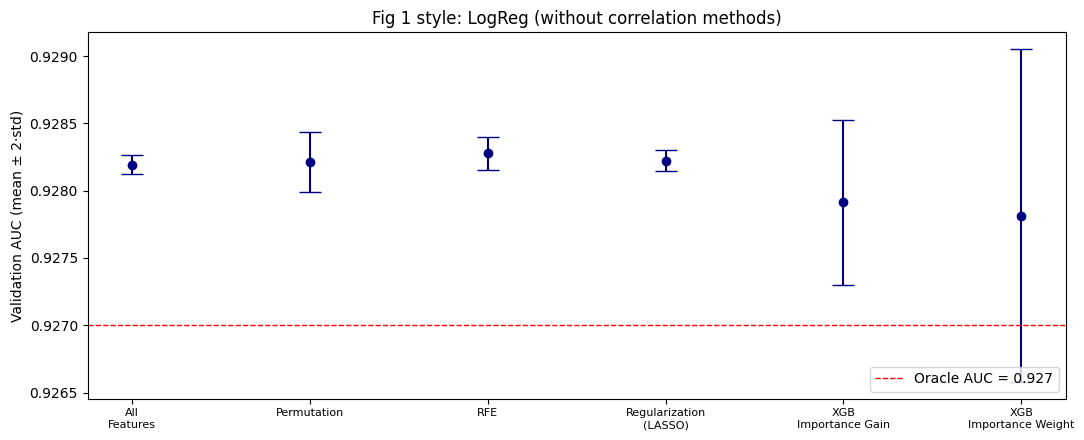

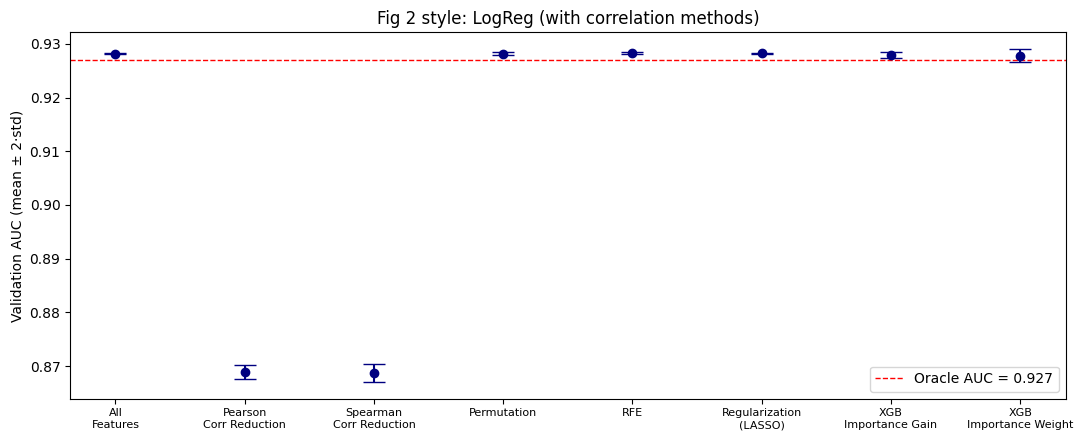

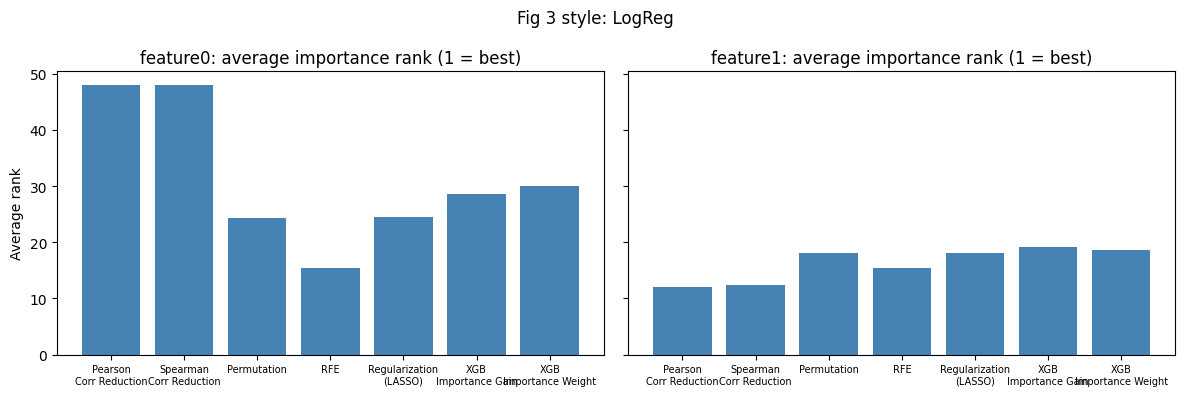

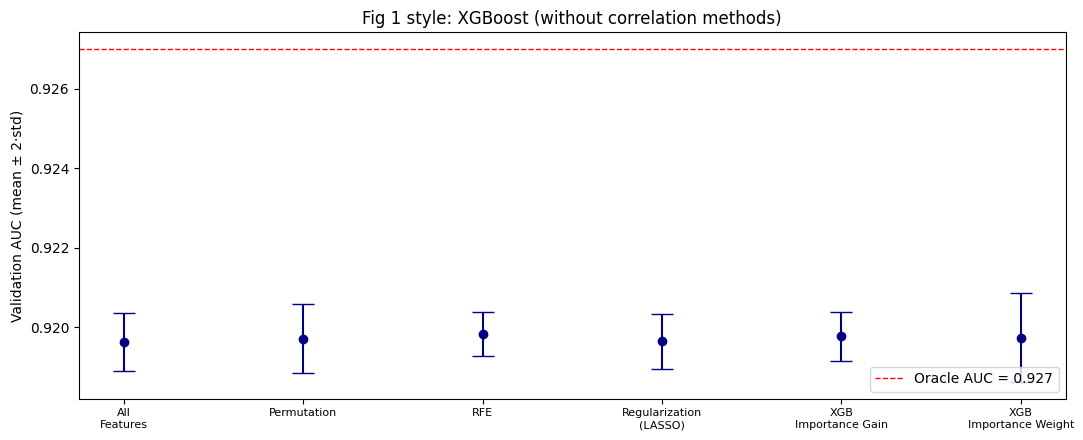

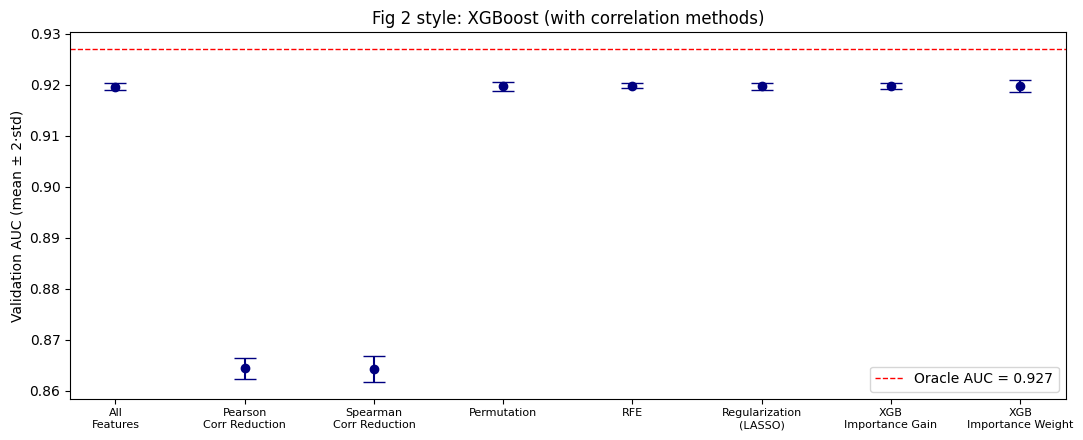

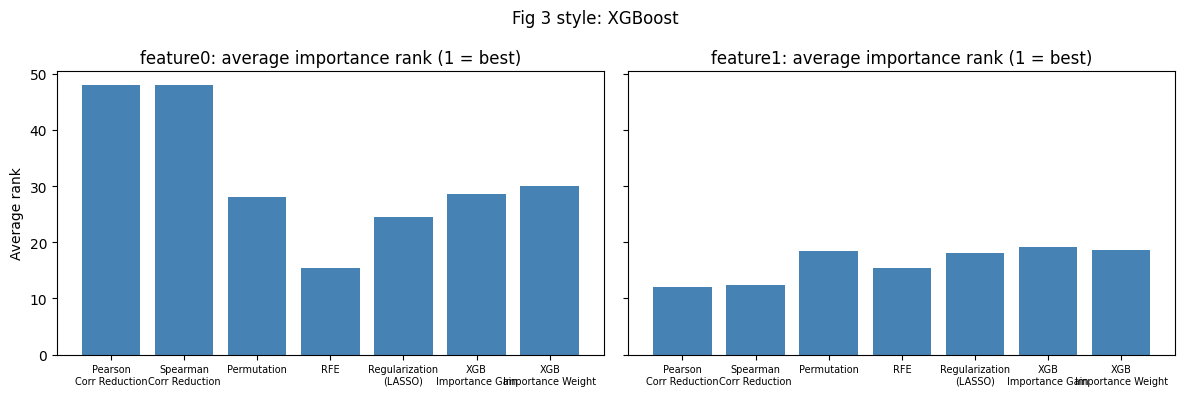


================ OBS 1 CHECK ================
LogReg: baaki methods ke AUC ka spread = 0.0005 (chhota => method choice trivial)
LogReg: Pearson/Spearman average AUC baaki se 0.0593 kam hai (exception)
XGBoost: baaki methods ke AUC ka spread = 0.0001 (chhota => method choice trivial)
XGBoost: Pearson/Spearman average AUC baaki se 0.0555 kam hai (exception)

Results aur plots yahan save hue: /content/drive/MyDrive/paper2A_group9_linear_fs/results


In [ ]:
# =====================================================================
# Paper 2A | Group 9 | FEATURE SELECTION on LINEAR synthetic data
# Paper: "A comparison of modeling preprocessing techniques" (2OS, 2023)
#
# Group ka kaam (screenshot ke hisaab se):
#   - Dataset  : Linear synthetic
#   - Algo     : Logistic Regression (saath mein XGBoost)
#   - Experiment: Feature selection  -> Paper ke Figs 1, 2, 3 reproduce karna
#   - Validate : Obs 1 -> "Simple data pe method ka choice trivial hai;
#                 sirf correlation-reduction methods (Pearson/Spearman) exception hain"
#
# Is code mein 8 cheezein compare hongi (har ek ko LogReg aur XGBoost dono pe):
#   1. All Features (baseline - koi selection nahi)
#   2. Pearson correlation reduction
#   3. Spearman rank correlation reduction
#   4. Permutation-based importance
#   5. RFE (Recursive Feature Elimination)
#   6. Regularization (LASSO / L1)
#   7. XGBoost importance - GAIN
#   8. XGBoost importance - WEIGHT
#
# Pehle wala script (colab_save_dataset_to_drive.py) chala lo, taaki
# Drive mein linear_fs_train.csv aur linear_fs_valid.csv bani hui ho.
# =====================================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFE
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")   # sklearn ke faltu warnings band

# ============================ SETTINGS ===============================
# Yahan se sab kuch control kar sakte ho.

DRIVE_FOLDER = "paper2A_group9_linear_fs"   # Drive mein wahi folder jahan dataset save kiya tha

N_FEATURES_TO_SELECT = 30   # Paper: sab methods ko "same number" of features choose karne ko force kiya
                            # (sirf LASSO ko free chhoda). Humare data mein 30 asli features hain.
N_RUNS = 10                 # Paper har method ko 30 baar chalata hai (error bars ke liye).
                            # Time bachane ke liye 10 rakha hai; chaho to 30 kar do.
TRAIN_ROWS = 50_000         # Har run mein itni rows pe final model train hoga
VALID_ROWS = 50_000         # Validation (test) rows jinpe AUC naapa jayega
SELECT_ROWS = 20_000        # Feature selection ke andar ke models (permutation, RFE, XGB importance, LASSO)
                            # sirf itni rows pe chalenge -> speed ke liye
CORR_THRESHOLD = 0.4        # Correlation reduction: agar 2 features ki |corr| isse zyada hai
                            # to ek ko drop karenge. (Humare pairs ki true corr = 0.5)
ORACLE_AUC = 0.927          # Dataset ka best-possible AUC (generator script ne print kiya tha)
SEED = 42

ALGOS = ["LogReg", "XGBoost"]   # Dono algorithms pe experiment chalega

METHODS = [
    "All Features",
    "Pearson Corr Reduction",
    "Spearman Corr Reduction",
    "Permutation",
    "RFE",
    "Regularization (LASSO)",
    "XGB Importance Gain",
    "XGB Importance Weight",
]
CORR_METHODS = ["Pearson Corr Reduction", "Spearman Corr Reduction"]


# ===================== DATA LOADING (Google Drive) ===================
def get_data_dir():
    """Colab mein Drive mount karta hai aur dataset folder ka path deta hai.
    Colab nahi hai (local PC) to current folder ke andar folder dhundhta hai."""
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        base = "/content/drive/MyDrive"
    except ImportError:
        base = os.path.abspath(".")
    return os.path.join(base, DRIVE_FOLDER)


def load_data(data_dir):
    """Drive se train aur valid CSV padhta hai.
    - Agar aapne multiple train files banayi hain (linear_fs_train_0.csv, _1.csv ...)
      to har run ko alag file milegi (paper jaisa).
    - Agar sirf ek train file hai to har run ko uska alag RANDOM SUBSET milega."""
    train_files = sorted(glob.glob(os.path.join(data_dir, "linear_fs_train_*.csv")))
    if not train_files:
        train_files = [os.path.join(data_dir, "linear_fs_train.csv")]
    valid_path = os.path.join(data_dir, "linear_fs_valid.csv")

    for p in train_files + [valid_path]:
        if not os.path.exists(p):
            raise FileNotFoundError(f"{p} nahi mila. Pehle dataset-generator script chalao.")

    trains = [pd.read_csv(p) for p in train_files]
    valid = pd.read_csv(valid_path)
    print(f"{len(trains)} train file(s) mili, valid shape = {valid.shape}")
    return trains, valid


# ===================== MODELS ========================================
def make_model(algo, seed):
    """Algo ke naam se model banata hai.
    Hyperparameters fixed rakhe hain (paper Bayesian optimisation use karta hai;
    hum speed ke liye simple sensible values use kar rahe hain)."""
    if algo == "LogReg":
        return LogisticRegression(max_iter=1000)
    return XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", tree_method="hist",
        n_jobs=-1, random_state=seed,
    )


# ===================== FEATURE SELECTION METHODS =====================
# Har method 2 cheezein return karta hai:
#   selected : chune hue features ki list
#   scores   : har feature ka importance score (bada = zyada important)
# Scores se hum baad mein RANKING nikalte hain (Fig 3 ke liye).

def sel_all(X, y, algo, n, seed):
    """Baseline: saare 55 features. Koi selection nahi."""
    return list(X.columns), None


def sel_corr_reduction(X, y, n, method, threshold):
    """Pearson / Spearman correlation reduction (paper Appendix C.1). 2 steps:
    Step 1 (multicollinearity): agar 2 features ki aapas mein |corr| > threshold hai,
            to jiski TARGET se correlation kam hai, use DROP kar do.
    Step 2: bache hue features mein se target se sabse zyada |corr| wale top-N rakho.

    NOTE: Humare data mein features (0,1), (2,3).. correlated pairs hain (r=0.5) aur
    DONO asli features hain. Step 1 har pair se ek asli feature bhi hata deta hai.
    Isi wajah se ye methods weak aate hain -> Obs 1 ka 'exception'."""
    feat_corr = X.corr(method=method).abs()                 # feature-feature correlation matrix
    target_corr = X.apply(lambda c: c.corr(y, method=method)).abs()   # feature-target correlation

    cols = list(X.columns)
    dropped = set()
    for i, a in enumerate(cols):
        if a in dropped:
            continue
        for b in cols[i + 1:]:
            if b in dropped:
                continue
            if feat_corr.loc[a, b] > threshold:
                # target se kam correlated wala feature hatao
                loser = a if target_corr[a] < target_corr[b] else b
                dropped.add(loser)
                if loser == a:
                    break      # 'a' hat gaya, uske baaki pairs check karne ka matlab nahi

    remaining = target_corr.drop(labels=list(dropped))
    selected = remaining.sort_values(ascending=False).head(n).index.tolist()

    scores = target_corr.copy()
    scores[list(dropped)] = -1          # dropped features ko sabse neeche rank milega
    return selected, scores


def sel_permutation(X, y, algo, n, seed):
    """Permutation importance (paper: Breiman 2001):
    Model train karo -> ek feature ke values shuffle karo -> AUC kitna gira?
    Jitna zyada gira, utna important feature.
    Hum model ko 70% data pe train karte hain aur shuffle held-out 30% pe karte hain."""
    cut = int(0.7 * len(X))
    Xa, ya, Xb, yb = X.iloc[:cut], y.iloc[:cut], X.iloc[cut:], y.iloc[cut:]
    model = make_model(algo, seed).fit(Xa, ya)
    r = permutation_importance(model, Xb, yb, scoring="roc_auc",
                               n_repeats=3, random_state=seed, n_jobs=-1)
    scores = pd.Series(r.importances_mean, index=X.columns)
    return scores.sort_values(ascending=False).head(n).index.tolist(), scores


def sel_rfe(X, y, algo, n, seed):
    """RFE (Recursive Feature Elimination): model fit karo, sabse kamzor 5 features
    hatao, phir se fit karo ... jab tak N features na bache."""
    rfe = RFE(make_model(algo, seed), n_features_to_select=n, step=5)
    rfe.fit(X, y)
    selected = list(X.columns[rfe.support_])
    # ranking_: 1 = selected, bada number = pehle eliminate hua. Score ke liye ulta kar do.
    scores = pd.Series(-rfe.ranking_.astype(float), index=X.columns)
    return selected, scores


def sel_lasso(X, y, algo, n, seed):
    """Regularization (LASSO / L1 logistic regression):
    L1 penalty kamzor features ke coefficient ko exactly 0 kar deti hai.
    Jinka coefficient != 0 hai wahi selected.
    IMPORTANT: Paper mein yahi ek method hai jise N fix nahi kiya gaya -
    ye khud decide karta hai kitne features rakhne hain (aksar bahut zyada)."""
    clf = LogisticRegressionCV(Cs=10, penalty="l1", solver="liblinear",
                               cv=3, scoring="roc_auc", max_iter=300,
                               random_state=seed).fit(X, y)
    scores = pd.Series(np.abs(clf.coef_[0]), index=X.columns)
    selected = scores[scores > 0].index.tolist()
    return selected, scores


def sel_xgb_importance(X, y, kind, n, seed):
    """XGBoost ka apna feature importance.
    kind = 'gain'   -> feature ke split se kitna improvement (purity) mila (paper isse prefer karta hai)
    kind = 'weight' -> feature kitni baar split ke liye use hua
    Weight ka dikkat: noise features bhi baar-baar split mein aa jate hain, bina fayde ke.
    NOTE: XGB importance hamesha XGBoost model se hi nikalte hain
    (chahe final model LogReg ho)."""
    model = make_model("XGBoost", seed).fit(X, y)
    raw = model.get_booster().get_score(importance_type=kind)
    scores = pd.Series(raw).reindex(X.columns).fillna(0.0)   # jo feature use hi nahi hua uska score 0
    return scores.sort_values(ascending=False).head(n).index.tolist(), scores


def run_selection(method, Xsel, ysel, algo, n, seed):
    """Method ke naam se sahi function call karta hai."""
    if method == "All Features":
        return sel_all(Xsel, ysel, algo, n, seed)
    if method == "Pearson Corr Reduction":
        return sel_corr_reduction(Xsel, ysel, n, "pearson", CORR_THRESHOLD)
    if method == "Spearman Corr Reduction":
        return sel_corr_reduction(Xsel, ysel, n, "spearman", CORR_THRESHOLD)
    if method == "Permutation":
        return sel_permutation(Xsel, ysel, algo, n, seed)
    if method == "RFE":
        return sel_rfe(Xsel, ysel, algo, n, seed)
    if method == "Regularization (LASSO)":
        return sel_lasso(Xsel, ysel, algo, n, seed)
    if method == "XGB Importance Gain":
        return sel_xgb_importance(Xsel, ysel, "gain", n, seed)
    if method == "XGB Importance Weight":
        return sel_xgb_importance(Xsel, ysel, "weight", n, seed)
    raise ValueError(method)


# ===================== MAIN EXPERIMENT ===============================
def run_experiment(data_dir=None, out_dir=None):
    data_dir = data_dir or get_data_dir()
    out_dir = out_dir or os.path.join(data_dir, "results")
    os.makedirs(out_dir, exist_ok=True)

    trains, valid = load_data(data_dir)
    feature_cols = [c for c in valid.columns if c != "target"]
    noise_cols = [c for c in feature_cols if c.startswith("noise")]

    # Validation set ek hi baar: standardize karne ke liye har run mein naya scaler lagega
    valid = valid.sample(min(VALID_ROWS, len(valid)), random_state=SEED)

    results, rank_rows = [], []

    for run in range(N_RUNS):
        seed = SEED + run

        # ---- is run ka training data ----
        if len(trains) > 1:                         # multiple files -> har run ko ek alag file
            tr = trains[run % len(trains)]
        else:                                       # ek file -> random subset (alag seed)
            tr = trains[0]
        tr = tr.sample(min(TRAIN_ROWS, len(tr)), random_state=seed)

        # ---- standardization (paper ka "standard preprocessing") ----
        # Scaler SIRF train pe fit hota hai, valid pe sirf transform (data leakage se bachne ke liye)
        scaler = StandardScaler().fit(tr[feature_cols])
        Xtr = pd.DataFrame(scaler.transform(tr[feature_cols]), columns=feature_cols, index=tr.index)
        ytr = tr["target"]
        Xva = pd.DataFrame(scaler.transform(valid[feature_cols]), columns=feature_cols, index=valid.index)
        yva = valid["target"]

        # ---- feature selection sirf chhote subset pe (speed ke liye) ----
        Xsel, ysel = Xtr.iloc[:SELECT_ROWS], ytr.iloc[:SELECT_ROWS]

        for algo in ALGOS:
            for method in METHODS:
                selected, scores = run_selection(method, Xsel, ysel, algo,
                                                 N_FEATURES_TO_SELECT, seed)

                # ---- chune hue features pe FINAL model train + AUC ----
                model = make_model(algo, seed).fit(Xtr[selected], ytr)
                auc_train = roc_auc_score(ytr, model.predict_proba(Xtr[selected])[:, 1])
                auc_valid = roc_auc_score(yva, model.predict_proba(Xva[selected])[:, 1])

                results.append(dict(
                    run=run, algo=algo, method=method,
                    n_selected=len(selected),
                    n_noise_selected=len(set(selected) & set(noise_cols)),   # Obs 2/3 ke liye
                    auc_train=auc_train, auc_valid=auc_valid,
                    gap=auc_train - auc_valid,                                # overfitting gap (Fig 6)
                ))

                # ---- ranking (Fig 3): rank 1 = sabse important ----
                if scores is not None:
                    ranks = scores.rank(ascending=False, method="average")
                    for f in ["feature0", "feature1", "noise13"]:
                        rank_rows.append(dict(run=run, algo=algo, method=method,
                                              feature=f, rank=ranks[f]))
        print(f"run {run + 1}/{N_RUNS} done")

    res = pd.DataFrame(results)
    rk = pd.DataFrame(rank_rows)
    res.to_csv(os.path.join(out_dir, "fs_results_all_runs.csv"), index=False)
    rk.to_csv(os.path.join(out_dir, "fs_feature_ranks.csv"), index=False)

    summarize_and_plot(res, rk, out_dir)
    return res, rk


# ===================== SUMMARY + PLOTS ===============================
def summarize_and_plot(res, rk, out_dir):
    # ---- Summary table: mean AUC, std, kitne features chune, kitne noise ----
    summary = (res.groupby(["algo", "method"])
                  .agg(auc_mean=("auc_valid", "mean"), auc_std=("auc_valid", "std"),
                       n_selected=("n_selected", "mean"),
                       noise_selected=("n_noise_selected", "mean"),
                       gap=("gap", "mean"))
                  .reindex(METHODS, level="method").round(4))
    print("\n================ SUMMARY (valid AUC) ================")
    print(summary.to_string())
    summary.to_csv(os.path.join(out_dir, "fs_summary.csv"))

    for algo in ALGOS:
        d = res[res.algo == algo]

        # ---- Fig 1: correlation methods ke BINA ----
        # ---- Fig 2: correlation methods ke SAATH ----
        for title, methods, fname in [
            (f"Fig 1 style: {algo} (without correlation methods)",
             [m for m in METHODS if m not in CORR_METHODS], f"fig1_{algo}.png"),
            (f"Fig 2 style: {algo} (with correlation methods)", METHODS, f"fig2_{algo}.png"),
        ]:
            stats = d.groupby("method")["auc_valid"].agg(["mean", "std"]).reindex(methods)
            fig, ax = plt.subplots(figsize=(11, 4.5))
            # paper mein error bar = mean +- 2*std hota hai
            ax.errorbar(range(len(methods)), stats["mean"], yerr=2 * stats["std"],
                        fmt="o", capsize=8, color="navy")
            ax.axhline(ORACLE_AUC, color="red", ls="--", lw=1, label=f"Oracle AUC = {ORACLE_AUC}")
            ax.set_xticks(range(len(methods)))
            ax.set_xticklabels([m.replace(" ", "\n", 1) for m in methods], fontsize=8)
            ax.set_ylabel("Validation AUC (mean ± 2·std)")
            ax.set_title(title)
            ax.legend(loc="lower right")
            plt.tight_layout()
            plt.savefig(os.path.join(out_dir, fname), dpi=150)
            plt.show()

        # ---- Fig 3: correlated features 0 aur 1 ki average importance ranking ----
        # Paper ka point: correlation methods pair mein se ek feature (feature0) drop kar dete hain,
        # isliye uski rank bahut kharab (bada number) aati hai.
        r = rk[(rk.algo == algo) & (rk.feature.isin(["feature0", "feature1"]))]
        avg = r.groupby(["method", "feature"])["rank"].mean().unstack().reindex(
            [m for m in METHODS if m != "All Features"])
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
        for ax, f in zip(axes, ["feature0", "feature1"]):
            ax.bar(range(len(avg)), avg[f], color="steelblue")
            ax.set_xticks(range(len(avg)))
            ax.set_xticklabels([m.replace(" ", "\n", 1) for m in avg.index], fontsize=7)
            ax.set_title(f"{f}: average importance rank (1 = best)")
        axes[0].set_ylabel("Average rank")
        plt.suptitle(f"Fig 3 style: {algo}")
        plt.tight_layout()
        plt.savefig(os.path.join(out_dir, f"fig3_{algo}.png"), dpi=150)
        plt.show()

    # ---- Obs 1 ka quick verdict ----
    print("\n================ OBS 1 CHECK ================")
    for algo in ALGOS:
        s = summary.loc[algo]["auc_mean"]
        non_corr = s.drop(CORR_METHODS + ["All Features"], errors="ignore")
        spread = non_corr.max() - non_corr.min()
        corr_drop = non_corr.mean() - s[CORR_METHODS].mean()
        print(f"{algo}: baaki methods ke AUC ka spread = {spread:.4f} (chhota => method choice trivial)")
        print(f"{algo}: Pearson/Spearman average AUC baaki se {corr_drop:.4f} kam hai (exception)")
    print("\nResults aur plots yahan save hue:", out_dir)


# =====================================================================
# Kaise padhna hai results ko (Observations jo validate karni hain):
#   Obs 1 : Fig 1 mein saare methods ka AUC lagbhag barabar; Fig 2 mein
#           Pearson aur Spearman neeche (exception).
#   Obs 2 : 'noise_selected' column + Permutation ka bada error bar (variance).
#   Obs 3 : LASSO ka 'n_selected' ~ 55 (lagbhag sab features) aur bada 'gap'.
#   Obs 4/5: XGB Gain vs Weight -> Gain consistent, Weight mein noise zyada.
# =====================================================================
if __name__ == "__main__":
    run_experiment()

In [ ]:
# Paper 2A | Group 9 -- full replication. Har '# %%' ek Colab cell (shell) hai.

# %%
# =====================================================================
# SHELL 1 | SETUP + SETTINGS
# Paper 2A | Group 9 | "A comparison of modeling preprocessing techniques" (2OS, 2023)
# Is notebook mein poora paper reproduce hota hai:
#   3 datasets (Linear, GAM Global, Jumpy GAM Local) + Lending Club (optional)
#   x 3 experiments (Feature selection, Categorical encoding, Null imputation)
# Sabse pehle isi shell ko chalao.
# =====================================================================
import os, sys, glob, time, json, math, warnings, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit

warnings.filterwarnings("ignore")

try:
    import xgboost
except ImportError:                     # Colab mein already hota hai, phir bhi safe side
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost

# ============================ SETTINGS ===============================
# PROFILE = kitna bada experiment chalana hai
#   "quick"    : ~15-25 min   (3 runs, 20K rows)   -> pehle ye chala ke check kar lo
#   "standard" : ~1.5-2.5 hr  (10 runs, 50K rows)  -> report ke liye theek
#   "paper"    : bahut lamba  (30 runs, 250K rows) -> exactly paper jaisa
PROFILE = os.environ.get("PAPER2A_PROFILE", "quick")
PROFILES = {
    "tiny":     dict(N_RUNS=2,  TRAIN_ROWS=3_000,   VALID_ROWS=3_000,   SELECT_ROWS=2_000),   # sirf code-test ke liye
    "quick":    dict(N_RUNS=3,  TRAIN_ROWS=20_000,  VALID_ROWS=20_000,  SELECT_ROWS=8_000),
    "standard": dict(N_RUNS=10, TRAIN_ROWS=50_000,  VALID_ROWS=50_000,  SELECT_ROWS=20_000),
    "paper":    dict(N_RUNS=30, TRAIN_ROWS=250_000, VALID_ROWS=250_000, SELECT_ROWS=50_000),
}
globals().update(PROFILES[PROFILE])   # N_RUNS, TRAIN_ROWS, VALID_ROWS, SELECT_ROWS

DRIVE_FOLDER = "paper2A_group9_all"        # Drive me ye folder ban jayega
ALGOS = ["XGBoost", "LogReg"]              # Paper sirf XGBoost use karta hai; Group 9 ke liye LogReg bhi.
                                           # Time bachana ho to ["XGBoost"] kar do.
FORMS = ["linear", "gam_global", "jumpy_gam"]
FORM_NAME = {"linear": "Linear", "gam_global": "GAM Global", "jumpy_gam": "Jumpy GAM Local"}
SEED = 42
RESUME = True                              # True: jo results Drive me ban chuke hain unhe dobara nahi chalayega
                                           # (Colab disconnect ho jaye to kaam aata hai)

# ---- method-specific knobs ----
CORR_THRESHOLD    = 0.4    # correlation reduction: |corr| isse upar => pair me se ek feature drop
XGB_IMP_SPLITS    = 5      # paper: 5-fold, 60% train splits (XGB importance)
NULL_RATE         = 0.5    # paper: 50% null
N_NULL_FEATURES   = 3      # paper: 3 features me null inject
CLUSTER_K         = 8      # clustering imputation: k-means clusters
TREE_IMPUTE_LEAVES = 10    # tree imputation: decision tree ke leaves

# ---- optional: Bayesian hyper-parameter tuning (paper ka tareeka). Slow hai, isliye default OFF ----
USE_TUNING = False
N_TUNING_TRIALS = 15

# ---- datasets ko Drive me save karna ----
SAVE_DATASETS = True

# ---- Lending Club (real-world) : Kaggle se loan.csv download karke Drive folder me daalo ----
LC_FILENAME = "loan.csv"       # DRIVE_FOLDER ke andar rakho
LC_ROWS     = 100_000          # itni rows sample hongi (poora 2.26M bahut bhaari hai)
LC_N_SELECT = 30               # feature selection me LC pe kitne features rakhne hain

# ---- Paper ke "oracle AUC" (synthetic data inhi par calibrate hota hai) ----
# FS aur Null-imputation ke numbers paper ki figures se; categorical-encoding me paper sirf jumpy (0.8575)
# batata hai, baaki dono ke liye 0.90 maana hai (assumption).
ORACLE_TARGET = {
    "fs":   {"linear": 0.927,  "gam_global": 0.9565, "jumpy_gam": 0.9211},
    "cat":  {"linear": 0.90,   "gam_global": 0.90,   "jumpy_gam": 0.8575},
    "null": {"linear": 0.9656, "gam_global": 0.9703, "jumpy_gam": 0.9484},
}

# ======================= GOOGLE DRIVE =================================
def get_base_dir():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        base = "/content/drive/MyDrive"
    except Exception:
        base = os.path.abspath(".")
        print("Colab nahi hai -> local folder use ho raha hai.")
    out = os.path.join(base, DRIVE_FOLDER)
    os.makedirs(out, exist_ok=True)
    return out

BASE_DIR = get_base_dir()
DATA_DIR = os.path.join(BASE_DIR, "datasets");  os.makedirs(DATA_DIR, exist_ok=True)
RES_DIR  = os.path.join(BASE_DIR, "results");   os.makedirs(RES_DIR,  exist_ok=True)
FIG_DIR  = os.path.join(BASE_DIR, "figures");   os.makedirs(FIG_DIR,  exist_ok=True)
print(f"PROFILE={PROFILE} | runs={N_RUNS} | train/valid rows={TRAIN_ROWS:,}/{VALID_ROWS:,} | algos={ALGOS}")
print("Saving to:", BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROFILE=quick | runs=3 | train/valid rows=20,000/20,000 | algos=['XGBoost', 'LogReg']
Saving to: /content/drive/MyDrive/paper2A_group9_all


In [ ]:
# %%
# =====================================================================
# SHELL 2 | SYNTHETIC DATA GENERATOR  (Paper Appendix B.1, Eq. 1-11, Tables 6-8)
#   3 functional forms : linear (Eq.1) | GAM global (Eq.2) | jumpy GAM local (Eq.3)
#   3 experiment-variants:
#       "fs"   = feature selection   (Eq. 9-11, Table 8: 3 weighted groups g, g', g'')
#       "cat"  = categorical encoding (Eq. 6-8, Table 7: 3 segments + indicator "gatekeepers")
#       "null" = null imputation      (Eq. 1-3, Table 6: 5 segments)
#   Har dataset: features N(0,1), pairs (0,1),(2,3).. correlated r=0.5, noise features,
#   coefficients Uniform[-3,3], y ~ Bernoulli(sigmoid(f)), classes balanced.
#   Signal strength ko paper ke "oracle AUC" par CALIBRATE kiya jata hai.
# =====================================================================
from sklearn.metrics import roc_auc_score

BLOCK = {"linear": 10, "gam_global": 5, "jumpy_gam": 10}   # ek copy of function kitne features use karta hai
CAT_GROUPS = [range(0, 3), range(3, 6), range(6, 10)]       # Eq. 6-8: segment 1/2/3 ke terms
SPEC = {   # (numeric informative features, noise features)   -> Tables 6, 7, 8
    "fs":   {"linear": (30, 25), "gam_global": (15, 10), "jumpy_gam": (30, 25)},
    "cat":  {"linear": (10, 5),  "gam_global": (5, 5),   "jumpy_gam": (10, 5)},
    "null": {"linear": (10, 5),  "gam_global": (5, 5),   "jumpy_gam": (10, 5)},
}
N_SEGMENTS = {"fs": 0, "cat": 3, "null": 5}
CORR_R = 0.5

def _inv(d):
    """1/d, par d~0 ke paas blow-up na ho (paper ke (b*|x|+1)^-1 term me singularity ho sakti hai)."""
    d = np.where(np.abs(d) < 1e-2, np.where(d >= 0, 1e-2, -1e-2), d)
    return 1.0 / d

# Har form = 10 additive terms. term(B, b): B = features ka block (columns 0..), b = coefficient.
TERMS = {
    "linear": [(lambda B, b, k=k: b * B[:, k]) for k in range(10)],
    "gam_global": [
        lambda B, b: b * np.abs(B[:, 0]),
        lambda B, b: b * B[:, 1] ** 2,
        lambda B, b: b * np.log(np.abs(B[:, 2]) + 1),
        lambda B, b: np.exp(b * B[:, 3]),
        lambda B, b: _inv(b * np.abs(B[:, 4]) + 1),
        lambda B, b: b * B[:, 0] * B[:, 1],
        lambda B, b: b * np.abs(B[:, 0] * B[:, 1] * B[:, 2]),
        lambda B, b: b * np.log(np.abs(B[:, 2] + B[:, 3] + B[:, 4]) + 1),
        lambda B, b: b * np.maximum(B[:, 3], B[:, 4]),
        lambda B, b: np.exp(b * (B[:, 4] - B[:, 2])),
    ],
    "jumpy_gam": [
        lambda B, b: b * np.abs(B[:, 0]) * (np.abs(B[:, 0]) < 2),
        lambda B, b: b * B[:, 1] ** 2 * (B[:, 1] > 1),
        lambda B, b: b * np.log(np.abs(B[:, 2]) + 1) * (np.abs(B[:, 2]) > 1),
        lambda B, b: np.exp(b * B[:, 3]) * (B[:, 3] < 0),
        lambda B, b: _inv(b * np.abs(B[:, 4]) + 1),
        lambda B, b: b * np.maximum(1, B[:, 5] + B[:, 6]),
        lambda B, b: b * (B[:, 6] < 1),
        lambda B, b: b * (np.abs(B[:, 7]) > 2),
        lambda B, b: b * B[:, 8] * (B[:, 8] < -1),
        lambda B, b: b * np.maximum(0, B[:, 9]),
    ],
}

def _coefs(exp, coef_seed):
    n = 33 if exp == "fs" else 10                       # Table 8: 33 coefficients, baaki 10
    return np.random.default_rng(coef_seed).uniform(-3, 3, size=n)

def _gen_numeric(rng, n, n_num, r=CORR_R):
    """Block-diagonal covariance (Eq. 4): pairs (0,1),(2,3).. corr=r; odd feature independent."""
    Z = rng.standard_normal((n, n_num)); X = Z.copy()
    for i in range(0, n_num - 1, 2):
        X[:, i + 1] = r * Z[:, i] + np.sqrt(1 - r * r) * Z[:, i + 1]
    return X

def raw_signal(form, exp, X, seg, beta):
    terms, blk = TERMS[form], BLOCK[form]
    if exp == "fs":                                      # f = b31*g + b32*g' + b33*g''
        f = np.zeros(len(X))
        for j in range(3):
            B = X[:, j * blk:(j + 1) * blk]
            g = sum(terms[k](B, beta[10 * j + k]) for k in range(10))
            f = f + beta[30 + j] * g
        return f
    B = X[:, :blk]
    if exp == "cat":                                     # indicator gatekeepers I(x_cat = s)
        f = np.zeros(len(X))
        for s, grp in enumerate(CAT_GROUPS, start=1):
            f = f + (seg == s) * sum(terms[k](B, beta[k]) for k in grp)
        return f
    return sum(terms[k](B, beta[k]) for k in range(10))  # "null": basic Eq. 1-3

def _expected_auc(p):
    """p ko true probability maan ke expected AUC (oracle) -- weighted trick."""
    n = len(p)
    return roc_auc_score(np.r_[np.ones(n), np.zeros(n)], np.r_[p, p], sample_weight=np.r_[p, 1 - p])

_CAL = {}
def _calibrate(form, exp, coef_seed, target_auc):
    """logit = s*z + c  : s se oracle AUC = target, c se classes 50/50. Ek baar nikalte hain, sab datasets me same."""
    key = (form, exp, coef_seed, round(target_auc, 4))
    if key in _CAL: return _CAL[key]
    n_num, _ = SPEC[exp][form]; beta = _coefs(exp, coef_seed)
    rng = np.random.default_rng(12345); n = 40_000
    X = _gen_numeric(rng, n, n_num)
    seg = rng.integers(1, N_SEGMENTS[exp] + 1, size=n) if exp != "fs" else np.zeros(n, int)
    f = raw_signal(form, exp, X, seg, beta)
    q1, med, q3 = np.percentile(f, [25, 50, 75])
    unit = max((q3 - q1) / 1.349, 1e-9)                  # robust scale (heavy tails ke liye)
    z = (f - med) / unit
    def intercept(s):
        lo, hi = -80.0, 80.0
        for _ in range(40):
            mid = (lo + hi) / 2
            if expit(s * z + mid).mean() > 0.5: hi = mid
            else: lo = mid
        return (lo + hi) / 2
    lo, hi = 0.02, 200.0
    for _ in range(24):
        s = (lo + hi) / 2
        if _expected_auc(expit(s * z + intercept(s))) < target_auc: lo = s
        else: hi = s
    s = (lo + hi) / 2
    _CAL[key] = (med, unit, s, intercept(s))
    return _CAL[key]

def make_dataset(form, exp, n, seed, coef_seed=0, target_auc=None):
    """Returns (df, meta, oracle_auc). df me feature*, noise*, [categorical], target."""
    target_auc = target_auc or ORACLE_TARGET[exp][form]
    n_num, n_noise = SPEC[exp][form]
    K = N_SEGMENTS[exp]
    if K: n = (n // K) * K            # segments EXACTLY barabar size (paper: data 'segment level' se bana)
    rng = np.random.default_rng(seed)
    X = _gen_numeric(rng, n, n_num)
    noise = rng.standard_normal((n, n_noise))
    # Barabar size segments => frequency encoding me teeno categories ko SAME value milti hai
    # (duplicate probabilities) -> paper ka Obs 6 (frequency encoding rigid data pe fail).
    seg = rng.permutation(np.repeat(np.arange(1, K + 1), n // K)) if K else np.zeros(n, int)
    f = raw_signal(form, exp, X, seg, _coefs(exp, coef_seed))
    med, unit, s, c = _calibrate(form, exp, coef_seed, target_auc)
    p = expit(s * (f - med) / unit + c)
    y = rng.binomial(1, p)
    num_cols = [f"feature{i}" for i in range(n_num)]
    noise_cols = [f"noise{i}" for i in range(n_noise)]
    df = pd.DataFrame(np.hstack([X, noise]), columns=num_cols + noise_cols)
    cat_cols = []
    if exp != "fs":
        df["categorical"] = seg; cat_cols = ["categorical"]
    df["target"] = y
    meta = dict(num_cols=num_cols, noise_cols=noise_cols, cat_cols=cat_cols, inject_nulls=(exp == "null"))
    return df, meta, roc_auc_score(y, p)

class SyntheticProvider:
    """get(run) -> train/valid. Train: har run ka alag sample. Valid: 3 alag sets (paper jaisa), same coefficients."""
    def __init__(self, form, exp):
        self.form, self.exp, self._valid = form, exp, {}
    def get(self, run):
        tr, meta, _ = make_dataset(self.form, self.exp, TRAIN_ROWS, seed=100 + run)
        v = run % 3
        if v not in self._valid:
            self._valid[v] = make_dataset(self.form, self.exp, VALID_ROWS, seed=10_000 + v)
        va, _, oracle = self._valid[v]
        return dict(tr=tr, va=va, meta=meta, oracle=oracle)
    def hpo_set(self, i):                                 # hyper-parameter tuning ke 3 alag datasets
        return make_dataset(self.form, self.exp, min(TRAIN_ROWS, 20_000), seed=50_000 + i)[:2]

print("Generator ready.")

Generator ready.


In [ ]:
# %%
# =====================================================================
# SHELL 3 | DATASETS GENERATE + SANITY CHECK + DRIVE ME SAVE
#   Har (form x experiment) ke liye: 1 train + 1 valid file save hoti hai.
#   Experiments in files ko padhte nahi -- wahi seeds se data dobara bana lete hain (same result).
# =====================================================================
rows = []
for exp in ["fs", "cat", "null"]:
    for form in FORMS:
        prov = SyntheticProvider(form, exp)
        d = prov.get(0)
        tr, va = d["tr"], d["va"]
        c01 = tr["feature0"].corr(tr["feature1"])
        rows.append(dict(experiment=exp, form=form, shape=tr.shape, balance=round(tr.target.mean(), 3),
                         oracle_AUC=round(d["oracle"], 4), paper_oracle=ORACLE_TARGET[exp][form],
                         corr_f0_f1=round(c01, 2)))
        if SAVE_DATASETS:
            for name, df in [("train", tr), ("valid", va)]:
                path = os.path.join(DATA_DIR, f"{form}_{exp}_{name}")
                try:
                    df.to_parquet(path + ".parquet", index=False)
                except Exception:
                    df.round(5).to_csv(path + ".csv.gz", index=False)
SANITY = pd.DataFrame(rows)
print(SANITY.to_string(index=False))
print("\nDatasets saved in:", DATA_DIR if SAVE_DATASETS else "(SAVE_DATASETS=False)")


experiment       form       shape  balance  oracle_AUC  paper_oracle  corr_f0_f1
        fs     linear (20000, 56)    0.500      0.9250        0.9270        0.50
        fs gam_global (20000, 26)    0.491      0.9567        0.9565        0.51
        fs  jumpy_gam (20000, 56)    0.505      0.9211        0.9211        0.50
       cat     linear (19998, 17)    0.500      0.8975        0.9000        0.50
       cat gam_global (19998, 12)    0.499      0.8997        0.9000        0.51
       cat  jumpy_gam (19998, 17)    0.502      0.8559        0.8575        0.50
      null     linear (20000, 17)    0.504      0.9647        0.9656        0.50
      null gam_global (20000, 12)    0.499      0.9699        0.9703        0.51
      null  jumpy_gam (20000, 17)    0.506      0.9484        0.9484        0.50

Datasets saved in: /content/drive/MyDrive/paper2A_group9_all/datasets


In [ ]:
# %%
# =====================================================================
# SHELL 4 | COMMON UTILITIES  (models, preprocessing, plotting helpers, tuning)
# =====================================================================
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from xgboost import XGBClassifier

BEST_PARAMS = {}                                  # (form, exp) -> tuned XGB params (tuning shell bharta hai)
DEFAULT_XGB = dict(n_estimators=200, max_depth=4, learning_rate=0.1, gamma=0.0)

def make_model(algo, seed, params=None):
    """Hyperparameters fixed (paper Bayesian-tune karta hai: gamma, lr, max_depth, n_estimators)."""
    if algo == "LogReg":
        return LogisticRegression(max_iter=1000)
    p = {**DEFAULT_XGB, **(params or {})}
    return XGBClassifier(**p, subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                         tree_method="hist", n_jobs=-1, random_state=seed)

def auc_of(model, X, y):
    return roc_auc_score(y, model.predict_proba(X)[:, 1])

def std_pair(Xtr, Xva):
    """Standardize: scaler sirf train pe fit (leakage nahi)."""
    sc = StandardScaler().fit(Xtr)
    f = lambda X: pd.DataFrame(sc.transform(X), columns=X.columns, index=X.index)
    return f(Xtr), f(Xva)

def ohe_pair(tr, va, cols):
    """Control group ka standard one-hot encoding."""
    if not cols: return tr, va
    A = pd.get_dummies(tr, columns=cols, dtype=float)
    B = pd.get_dummies(va, columns=cols, dtype=float).reindex(columns=A.columns, fill_value=0.0)
    return A, B

def prep_standard(tr, va, meta):
    """Paper ka 'standard preprocessing': column consistency + OHE categoricals + standardize.
    (Real data me NaN ho to median se bharte hain -- synthetic me NaN hota hi nahi.)"""
    Xtr, Xva = tr.drop(columns="target").copy(), va.drop(columns="target").copy()
    cats = meta["cat_cols"]
    for c in cats:
        Xtr[c] = Xtr[c].astype(object).where(Xtr[c].notna(), "missing")
        Xva[c] = Xva[c].astype(object).where(Xva[c].notna(), "missing")
    num = [c for c in Xtr.columns if c not in cats]
    if Xtr[num].isna().any().any():
        med = Xtr[num].median(); Xtr[num] = Xtr[num].fillna(med); Xva[num] = Xva[num].fillna(med)
    Xtr, Xva = ohe_pair(Xtr, Xva, cats)
    return std_pair(Xtr, Xva)

# ---------------------------- plotting helpers ----------------------------
def plot_methods(ax, stats, methods, title, oracle=None, ylabel="Validation AUC (mean ± 2·std)"):
    """Paper style: dot = mean, whisker = mean ± 2*std."""
    m = stats["mean"].reindex(methods); s = stats["std"].reindex(methods).fillna(0)
    ax.errorbar(range(len(methods)), m, yerr=2 * s, fmt="o", capsize=8, color="navy")
    if oracle:
        ax.axhline(oracle, color="red", ls="--", lw=1, label=f"Oracle AUC = {oracle:.4f}")
        ax.legend(loc="lower right", fontsize=8)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels([x.replace(" ", "\n", 1) for x in methods], fontsize=7)
    ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)

def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight"); plt.show()

def csv_path(name): return os.path.join(RES_DIR, name)

def cached(name, fn):
    """RESUME=True ho aur file pehle se hai to wahi padh lo, warna fn() chalao aur save karo."""
    p = csv_path(name)
    if RESUME and os.path.exists(p):
        print(f"  [skip] {name} already exists"); return pd.read_csv(p)
    df = fn(); df.to_csv(p, index=False); return df

# ---------------------------- optional Bayesian tuning ----------------------------
def tune_xgb(form, exp, n_trials=N_TUNING_TRIALS):
    """Paper: Bayesian optimisation (gamma, learning rate, max depth, n_estimators) alag 'hyperparameter' datasets pe.
    Yahan Optuna (TPE = Bayesian) use kiya hai."""
    try:
        import optuna
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna"]); import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    prov = SyntheticProvider(form, exp)
    sets = []
    for i in range(3):
        df, meta = prov.hpo_set(i)
        cut = int(0.7 * len(df))
        Xtr, Xva = prep_standard(df.iloc[:cut], df.iloc[cut:], meta)
        sets.append((Xtr, df.iloc[:cut]["target"], Xva, df.iloc[cut:]["target"]))
    def objective(trial):
        p = dict(gamma=trial.suggest_float("gamma", 0, 5),
                 learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                 max_depth=trial.suggest_int("max_depth", 2, 8),
                 n_estimators=trial.suggest_int("n_estimators", 50, 400))
        return np.mean([auc_of(make_model("XGBoost", 0, p).fit(a, b), c, d) for a, b, c, d in sets])
    st = optuna.create_study(direction="maximize"); st.optimize(objective, n_trials=n_trials)
    BEST_PARAMS[(form, exp)] = st.best_params
    return st.best_params

def params_for(form, exp): return BEST_PARAMS.get((form, exp))

if USE_TUNING:
    for _exp in ["fs", "cat", "null"]:
        for _form in FORMS:
            print(f"tuning {_form}/{_exp} ->", tune_xgb(_form, _exp))
    json.dump({f"{k[0]}|{k[1]}": v for k, v in BEST_PARAMS.items()}, open(csv_path("best_xgb_params.json"), "w"), indent=1)
print("Utilities ready.  (USE_TUNING =", USE_TUNING, ")")


Utilities ready.  (USE_TUNING = False )


In [ ]:
# %%
# =====================================================================
# SHELL 5 | EXPERIMENT A: FEATURE SELECTION  (Paper sec 2.1, Obs 1-5, Figs 1-9)
#   8 methods: All Features | Pearson / Spearman corr reduction | Permutation | RFE |
#              Regularization (LASSO) | XGB importance (gain) | XGB importance (weight)
#   3 datasets x ALGOS x N_RUNS.  Sabko same N features choose karne ko force kiya jata hai
#   (sirf LASSO ko free chhoda -- paper jaisa).
# =====================================================================
from sklearn.feature_selection import RFE
from sklearn.inspection import permutation_importance
from sklearn.model_selection import ShuffleSplit

FS_METHODS = ["All Features", "Pearson Corr Reduction", "Spearman Corr Reduction", "Permutation", "RFE",
              "Regularization (LASSO)", "XGB Importance Gain", "XGB Importance Weight"]
CORR_METHODS = ["Pearson Corr Reduction", "Spearman Corr Reduction"]
RANK_VARS = ["feature0", "feature1", "noise13", "noise24"]     # Fig 3, 5, 8 ke features

def fs_corr_reduction(X, y, n, method):
    """Step 1: |corr(a,b)| > threshold ho to target se kam correlated feature DROP.
       Step 2: bache hue me se target se sabse zyada correlated top-N rakho."""
    fc = X.corr(method=method).abs()
    tc = X.apply(lambda c: c.corr(y, method=method)).abs().fillna(0)
    cols, dropped = list(X.columns), set()
    for i, a in enumerate(cols):
        if a in dropped: continue
        for b in cols[i + 1:]:
            if b in dropped: continue
            if fc.loc[a, b] > CORR_THRESHOLD:
                loser = a if tc[a] < tc[b] else b
                dropped.add(loser)
                if loser == a: break
    sel = tc.drop(labels=list(dropped)).sort_values(ascending=False).head(n).index.tolist()
    scores = tc.copy(); scores[list(dropped)] = -1          # dropped = sabse neeche rank
    return sel, scores

def fs_permutation(X, y, algo, n, seed, params):
    cut = int(0.7 * len(X))
    model = make_model(algo, seed, params).fit(X.iloc[:cut], y.iloc[:cut])
    r = permutation_importance(model, X.iloc[cut:], y.iloc[cut:], scoring="roc_auc",
                               n_repeats=3, random_state=seed, n_jobs=-1)
    sc = pd.Series(r.importances_mean, index=X.columns)
    return sc.sort_values(ascending=False).head(n).index.tolist(), sc

def fs_rfe(X, y, algo, n, seed, params):
    rfe = RFE(make_model(algo, seed, params), n_features_to_select=n, step=max(1, X.shape[1] // 10)).fit(X, y)
    return list(X.columns[rfe.support_]), pd.Series(-rfe.ranking_.astype(float), index=X.columns)

def fs_lasso(X, y, seed):
    """L1 logistic regression: coef != 0 wale features. N fix NAHI hota (paper jaisa)."""
    clf = LogisticRegressionCV(Cs=10, penalty="l1", solver="liblinear", cv=3, scoring="roc_auc",
                               max_iter=300, random_state=seed).fit(X, y)
    sc = pd.Series(np.abs(clf.coef_[0]), index=X.columns)
    return sc[sc > 0].index.tolist(), sc

def fs_xgb_importance(X, y, seed, params):
    """Paper: 5-fold CV, 60% train splits; scores normalize (score/sum) phir average. Gain aur weight dono ek saath."""
    acc = {"gain": [], "weight": []}
    for tr_i, _ in ShuffleSplit(n_splits=XGB_IMP_SPLITS, train_size=0.6, random_state=seed).split(X):
        m = make_model("XGBoost", seed, params).fit(X.iloc[tr_i], y.iloc[tr_i])
        for k in acc:
            s = pd.Series(m.get_booster().get_score(importance_type=k)).reindex(X.columns).fillna(0.0)
            acc[k].append(s / s.sum() if s.sum() > 0 else s)
    return {k: pd.concat(v, axis=1).mean(axis=1) for k, v in acc.items()}

def select_features(method, X, y, algo, n, seed, params, cache):
    if method == "All Features":            return list(X.columns), None
    if method == "Pearson Corr Reduction":  return fs_corr_reduction(X, y, n, "pearson")
    if method == "Spearman Corr Reduction": return fs_corr_reduction(X, y, n, "spearman")
    if method == "Permutation":             return fs_permutation(X, y, algo, n, seed, params)
    if method == "RFE":                     return fs_rfe(X, y, algo, n, seed, params)
    if method == "Regularization (LASSO)":  return fs_lasso(X, y, seed)
    if "imp" not in cache: cache["imp"] = fs_xgb_importance(X, y, seed, params)     # ek baar nikalo, dono me use
    sc = cache["imp"]["gain" if method.endswith("Gain") else "weight"]
    return sc.sort_values(ascending=False).head(n).index.tolist(), sc

def run_feature_selection(get_split, n_select, params=None):
    res, rk = [], []
    for run in range(N_RUNS):
        d = get_split(run); tr, va, meta = d["tr"], d["va"], d["meta"]
        seed = SEED + run
        Xtr, Xva = prep_standard(tr, va, meta); ytr, yva = tr["target"], va["target"]
        Xs, ys = Xtr.iloc[:SELECT_ROWS], ytr.iloc[:SELECT_ROWS]       # selection chhote subset pe (speed)
        cache = {}
        for algo in ALGOS:
            for method in FS_METHODS:
                sel, sc = select_features(method, Xs, ys, algo, n_select, seed, params, cache)
                m = make_model(algo, seed, params).fit(Xtr[sel], ytr)
                a_tr, a_va = auc_of(m, Xtr[sel], ytr), auc_of(m, Xva[sel], yva)
                res.append(dict(run=run, algo=algo, method=method, n_selected=len(sel),
                                n_noise_selected=len(set(sel) & set(meta["noise_cols"])),
                                auc_train=a_tr, auc_valid=a_va, gap=a_tr - a_va, oracle=d["oracle"]))
                if sc is not None:
                    ranks = sc.rank(ascending=False, method="average")      # 1 = sabse important
                    for v in RANK_VARS:
                        if v in ranks.index:
                            rk.append(dict(run=run, algo=algo, method=method, variable=v, rank=ranks[v]))
        print(f"    run {run + 1}/{N_RUNS} done", flush=True)
    return pd.DataFrame(res), pd.DataFrame(rk)

# ------------------------------ saare datasets pe chalao ------------------------------
FS_RES, FS_RANK = [], []
for form in FORMS:
    t0 = time.time(); print(f"[FS] {FORM_NAME[form]}")
    n_sel = SPEC["fs"][form][0]                                        # asli (informative) features ki sankhya
    prov = SyntheticProvider(form, "fs")
    if RESUME and os.path.exists(csv_path(f"fs_{form}_results.csv")):
        r, k = pd.read_csv(csv_path(f"fs_{form}_results.csv")), pd.read_csv(csv_path(f"fs_{form}_ranks.csv"))
        print("  [skip] results already exist")
    else:
        r, k = run_feature_selection(prov.get, n_sel, params_for(form, "fs"))
        r.to_csv(csv_path(f"fs_{form}_results.csv"), index=False); k.to_csv(csv_path(f"fs_{form}_ranks.csv"), index=False)
    r["form"] = form; k["form"] = form
    FS_RES.append(r); FS_RANK.append(k)
    print(f"  done in {time.time() - t0:.0f}s")
FS_RES, FS_RANK = pd.concat(FS_RES, ignore_index=True), pd.concat(FS_RANK, ignore_index=True)

summary = (FS_RES.groupby(["form", "algo", "method"])
           .agg(auc_mean=("auc_valid", "mean"), auc_std=("auc_valid", "std"), n_selected=("n_selected", "mean"),
                noise_selected=("n_noise_selected", "mean"), gap=("gap", "mean")).round(4))
summary.to_csv(csv_path("fs_summary.csv"))
print("\n====== FEATURE SELECTION SUMMARY (valid AUC) ======")
print(summary.to_string())


[FS] Linear
  [skip] results already exist
  done in 0s
[FS] GAM Global
  [skip] results already exist
  done in 0s
[FS] Jumpy GAM Local
  [skip] results already exist
  done in 0s

====== FEATURE SELECTION SUMMARY (valid AUC) ======
                                            auc_mean  auc_std  n_selected  noise_selected     gap
form       algo    method                                                                        
gam_global LogReg  All Features               0.8476   0.0007     25.0000         10.0000 -0.0049
                   Pearson Corr Reduction     0.8128   0.0007     15.0000          7.0000 -0.0030
                   Permutation                0.8476   0.0007     15.0000          3.6667 -0.0051
                   RFE                        0.8476   0.0007     15.0000          2.3333 -0.0051
                   Regularization (LASSO)     0.8476   0.0007     17.6667          4.6667 -0.0050
                   Spearman Corr Reduction    0.8129   0.0008     15.0000       

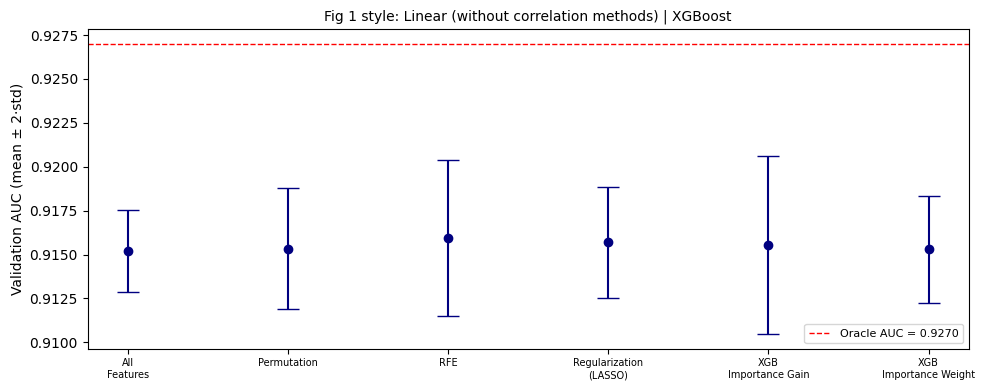

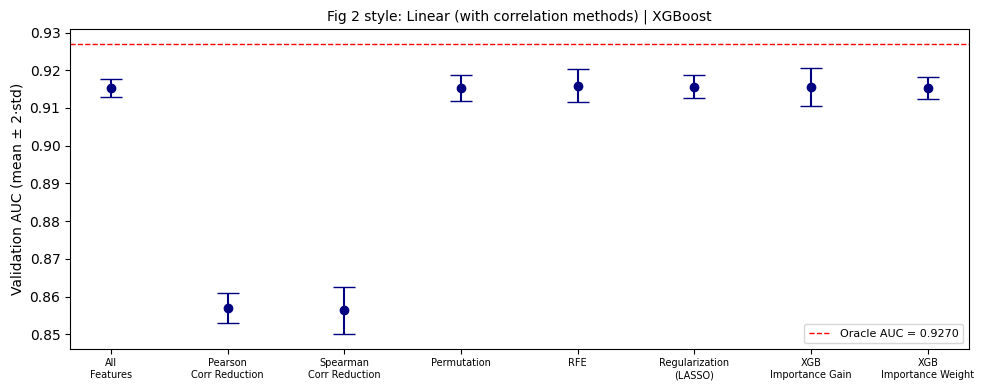

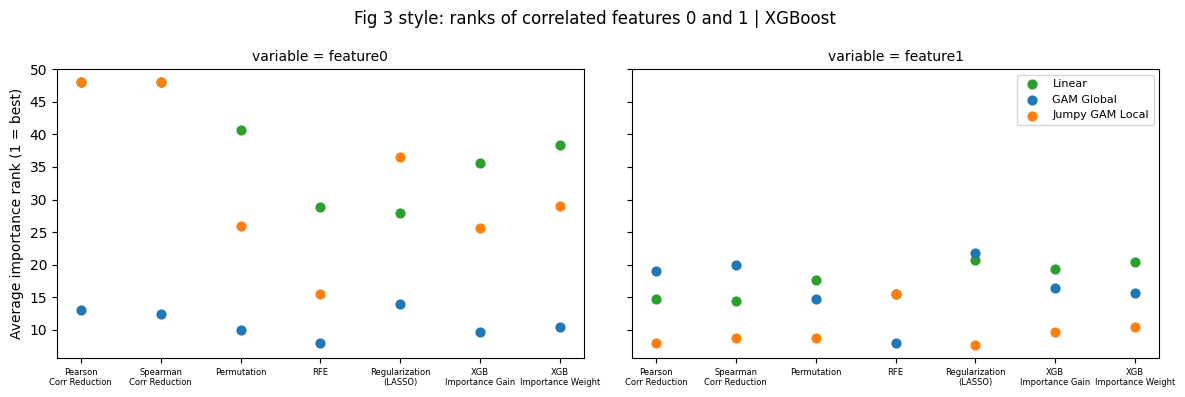

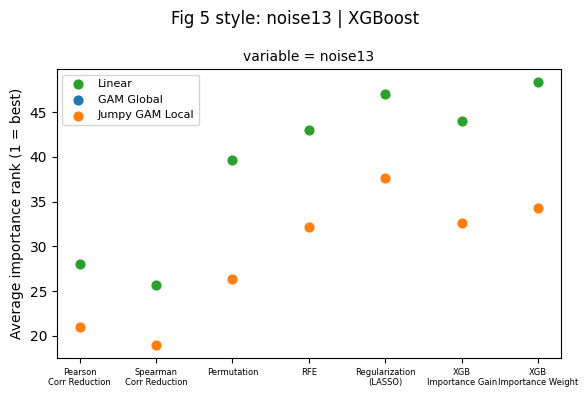

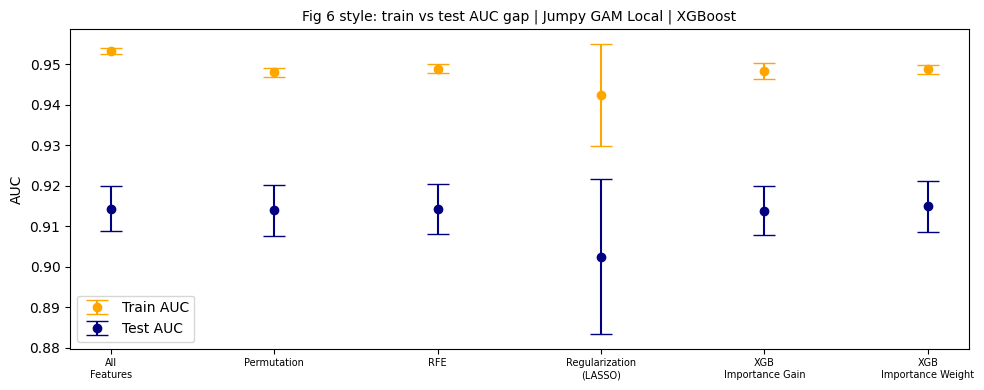

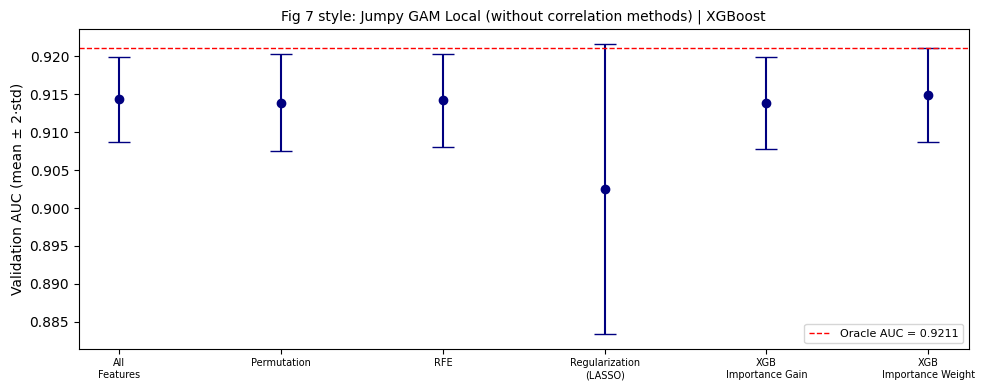

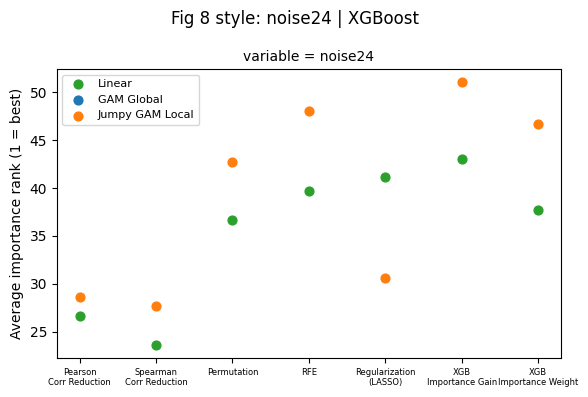

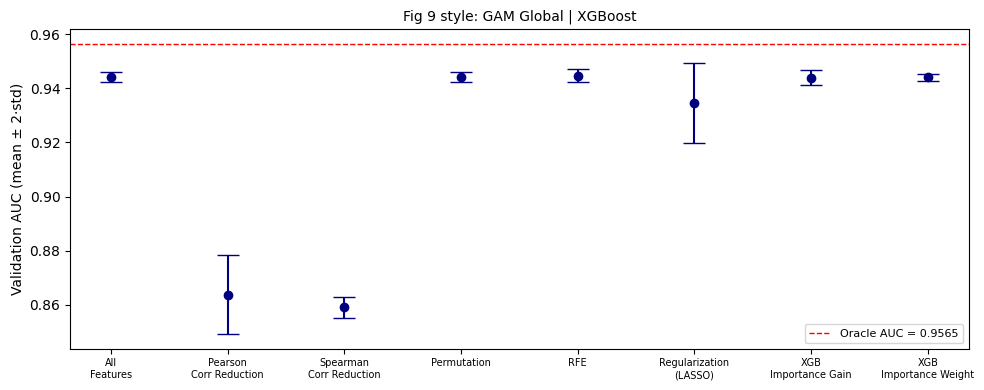

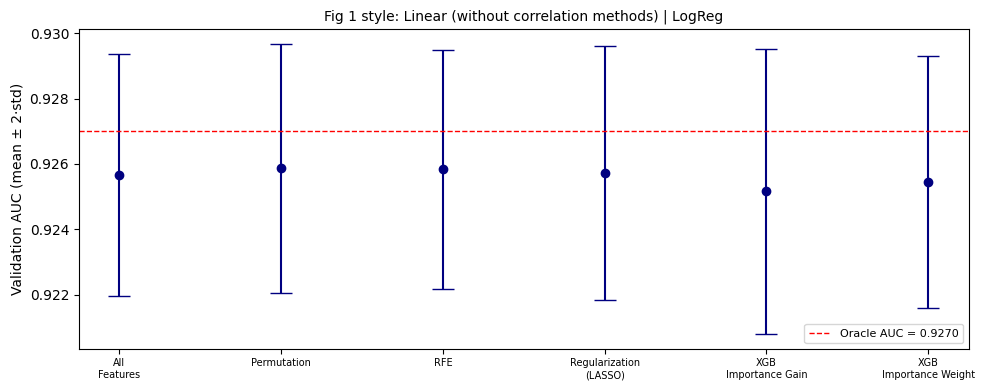

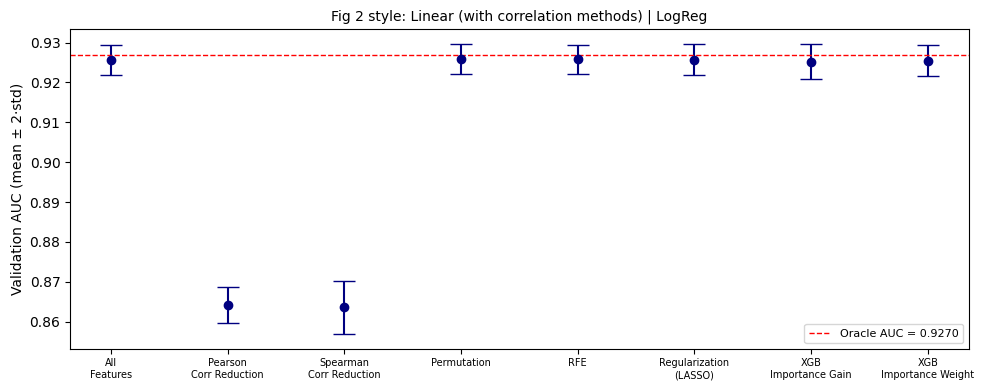

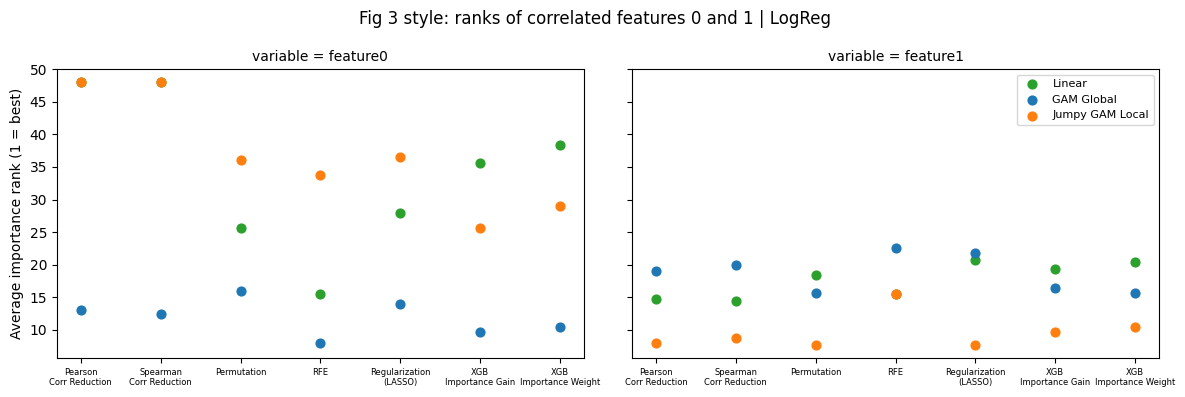

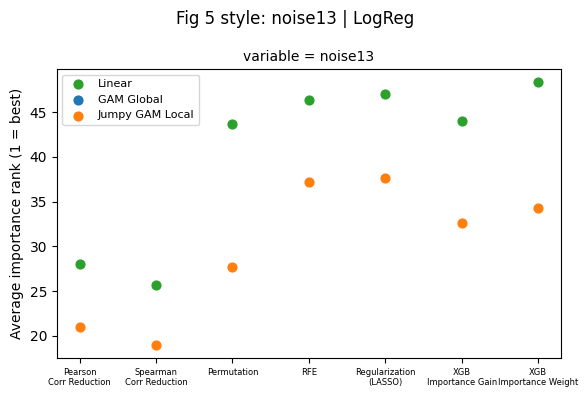

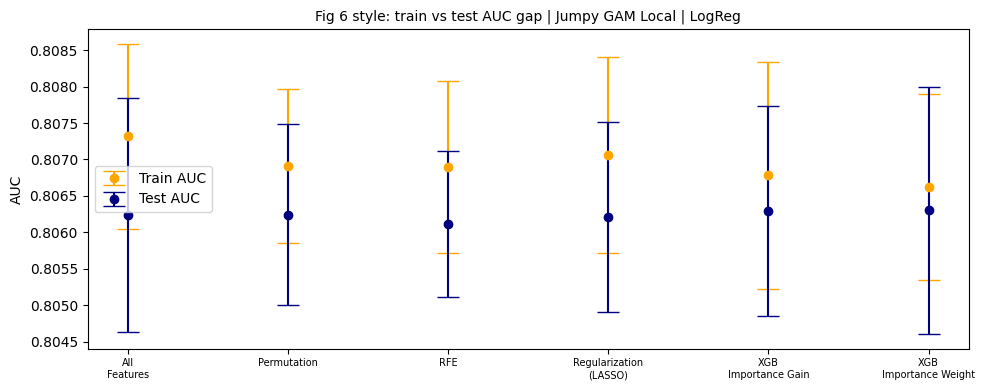

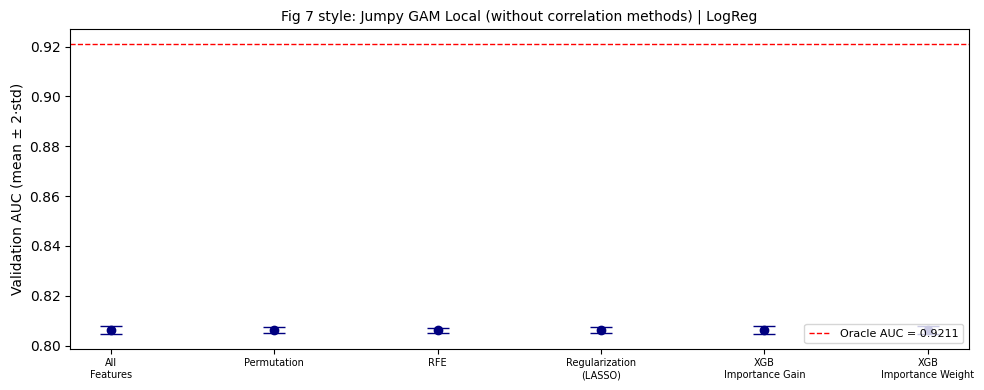

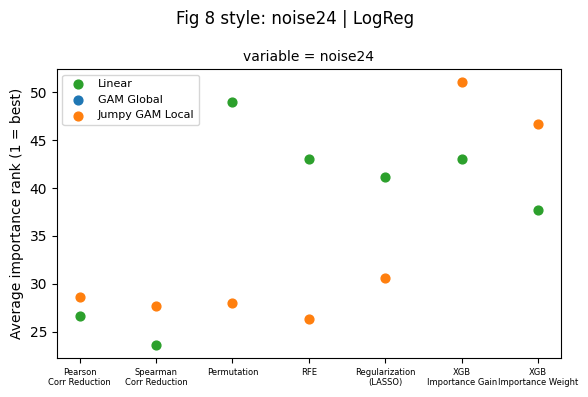

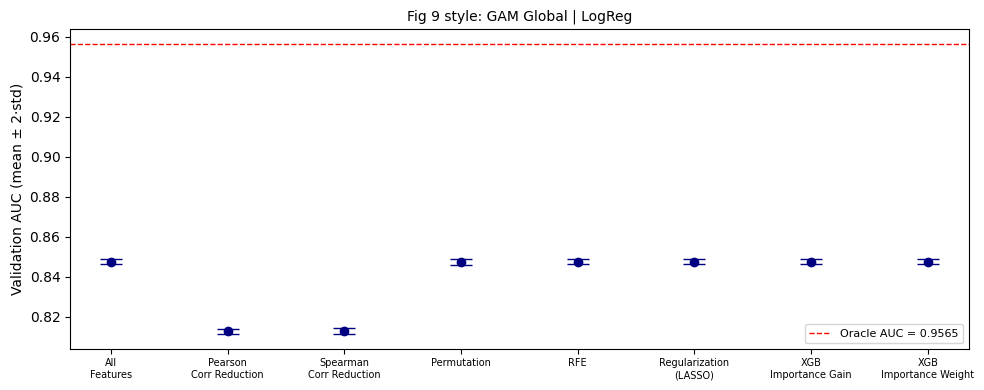


====== OBSERVATION CHECKS (feature selection) ======
  obs    dataset                                                            evidence verdict    algo
Obs 1     linear     spread(non-corr methods)=0.0007, corr methods 0.0589 AUC neeche ✔ holds XGBoost
Obs 1 gam_global     spread(non-corr methods)=0.0102, corr methods 0.0810 AUC neeche ✘ check XGBoost
Obs 1  jumpy_gam     spread(non-corr methods)=0.0124, corr methods 0.0196 AUC neeche ✘ check XGBoost
Obs 2  jumpy_gam  Permutation std=0.0032 vs baaki median std=0.0031; noise chuna=7.3 ✔ holds XGBoost
Obs 3     linear           LASSO ne 44.7/55 features chune, AUC 0.9157 vs All 0.9152 ✔ holds XGBoost
Obs 3 gam_global           LASSO ne 17.7/25 features chune, AUC 0.9345 vs All 0.9442 ✔ holds XGBoost
Obs 3  jumpy_gam           LASSO ne 37.7/55 features chune, AUC 0.9025 vs All 0.9143 ✔ holds XGBoost
Obs 4     linear        Gain AUC 0.9155 (noise 2.0) vs Weight AUC 0.9153 (noise 2.3) ✔ holds XGBoost
Obs 4 gam_global        Gain AUC 0.94

In [ ]:
# %%
# =====================================================================
# SHELL 6 | FEATURE SELECTION: FIGURES + OBSERVATION CHECKS (Obs 1-5)
#   Fig 1 : Linear, correlation methods ke BINA          Fig 2 : Linear, correlation methods ke SAATH
#   Fig 3 : feature0/feature1 ka average rank (3 datasets)
#   Fig 5 : noise13 rank    Fig 8 : noise24 rank
#   Fig 6 : Jumpy GAM train-vs-test AUC gap   Fig 7 : Jumpy GAM (w/o corr)   Fig 9 : GAM Global (with corr)
# =====================================================================
NON_CORR = [m for m in FS_METHODS if m not in CORR_METHODS]
ORACLE_FS = lambda form: ORACLE_TARGET["fs"][form]
COLORS = {"linear": "tab:green", "gam_global": "tab:blue", "jumpy_gam": "tab:orange"}

def fs_auc_plot(form, algo, methods, title, fname):
    d = FS_RES[(FS_RES.form == form) & (FS_RES.algo == algo)]
    fig, ax = plt.subplots(figsize=(10, 4))
    plot_methods(ax, d.groupby("method")["auc_valid"].agg(["mean", "std"]), methods, title, ORACLE_FS(form))
    save_fig(fig, fname)

def fs_gap_plot(form, algo, fname):                     # Fig 6: train vs test AUC
    d = FS_RES[(FS_RES.form == form) & (FS_RES.algo == algo)]
    fig, ax = plt.subplots(figsize=(10, 4))
    for col, c, lab in [("auc_train", "orange", "Train AUC"), ("auc_valid", "navy", "Test AUC")]:
        g = d.groupby("method")[col].agg(["mean", "std"]).reindex(NON_CORR)
        ax.errorbar(range(len(NON_CORR)), g["mean"], yerr=2 * g["std"].fillna(0), fmt="o", capsize=8, color=c, label=lab)
    ax.set_xticks(range(len(NON_CORR))); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in NON_CORR], fontsize=7)
    ax.set_ylabel("AUC"); ax.legend(); ax.set_title(f"Fig 6 style: train vs test AUC gap | {FORM_NAME[form]} | {algo}", fontsize=10)
    save_fig(fig, fname)

def fs_rank_plot(variables, algo, fname, title):        # Fig 3 / 5 / 8
    d = FS_RANK[(FS_RANK.algo == algo) & (FS_RANK.variable.isin(variables))]
    meths = [m for m in FS_METHODS if m != "All Features"]
    fig, axes = plt.subplots(1, len(variables), figsize=(6 * len(variables), 4), sharey=True, squeeze=False)
    for ax, v in zip(axes[0], variables):
        for form in FORMS:
            g = d[(d.variable == v) & (d.form == form)].groupby("method")["rank"].mean().reindex(meths)
            ax.scatter(range(len(meths)), g.values, color=COLORS[form], label=FORM_NAME[form], s=40)
        ax.set_xticks(range(len(meths))); ax.set_xticklabels([m.replace(" ", "\n", 1) for m in meths], fontsize=6)
        ax.set_title(f"variable = {v}", fontsize=10)
    axes[0][0].set_ylabel("Average importance rank (1 = best)"); axes[0][-1].legend(fontsize=8)
    fig.suptitle(f"{title} | {algo}")
    save_fig(fig, fname)

for algo in ALGOS:
    fs_auc_plot("linear", algo, NON_CORR, f"Fig 1 style: Linear (without correlation methods) | {algo}", f"fig1_linear_{algo}.png")
    fs_auc_plot("linear", algo, FS_METHODS, f"Fig 2 style: Linear (with correlation methods) | {algo}", f"fig2_linear_{algo}.png")
    fs_rank_plot(["feature0", "feature1"], algo, f"fig3_corr_pair_ranks_{algo}.png", "Fig 3 style: ranks of correlated features 0 and 1")
    fs_rank_plot(["noise13"], algo, f"fig5_noise13_{algo}.png", "Fig 5 style: noise13")
    fs_gap_plot("jumpy_gam", algo, f"fig6_jumpy_gap_{algo}.png")
    fs_auc_plot("jumpy_gam", algo, NON_CORR, f"Fig 7 style: Jumpy GAM Local (without correlation methods) | {algo}", f"fig7_jumpy_{algo}.png")
    fs_rank_plot(["noise24"], algo, f"fig8_noise24_{algo}.png", "Fig 8 style: noise24")
    fs_auc_plot("gam_global", algo, FS_METHODS, f"Fig 9 style: GAM Global | {algo}", f"fig9_gam_global_{algo}.png")

# ------------------------------ Observation checks (paper ki XGBoost wali baat) ------------------------------
def fs_observations(algo):
    out = []
    S = FS_RES[FS_RES.algo == algo].groupby(["form", "method"]).agg(
        m=("auc_valid", "mean"), s=("auc_valid", "std"), ns=("n_selected", "mean"),
        nz=("n_noise_selected", "mean"), gap=("gap", "mean"))
    for form in FORMS:
        s = S.loc[form]
        spread = s.loc[[m for m in NON_CORR if m != "All Features"], "m"].agg(lambda x: x.max() - x.min())
        drop = s.loc[[m for m in NON_CORR if m != "All Features"], "m"].mean() - s.loc[CORR_METHODS, "m"].mean()
        out.append(dict(obs="Obs 1", dataset=form, evidence=f"spread(non-corr methods)={spread:.4f}, corr methods {drop:.4f} AUC neeche",
                        verdict="✔ holds" if (spread < 0.01 and (drop > 0.005 or form == "gam_global")) else "✘ check"))
    j = S.loc["jumpy_gam"]
    others = j.loc[[m for m in NON_CORR if m not in ("Permutation", "All Features")], "s"].median()
    out.append(dict(obs="Obs 2", dataset="jumpy_gam", evidence=f"Permutation std={j.loc['Permutation','s']:.4f} vs baaki median std={others:.4f}; noise chuna={j.loc['Permutation','nz']:.1f}",
                    verdict="✔ holds" if j.loc["Permutation", "s"] > others else "✘ check"))
    for form in FORMS:
        l = S.loc[(form, "Regularization (LASSO)")]; a = S.loc[(form, "All Features")]
        total = a["ns"]
        out.append(dict(obs="Obs 3", dataset=form, evidence=f"LASSO ne {l.ns:.1f}/{total:.0f} features chune, AUC {l.m:.4f} vs All {a.m:.4f}",
                        verdict="✔ holds" if l.ns > 0.6 * total else "✘ check"))
    for form in FORMS:
        g, w = S.loc[(form, "XGB Importance Gain")], S.loc[(form, "XGB Importance Weight")]
        out.append(dict(obs="Obs 4", dataset=form, evidence=f"Gain AUC {g.m:.4f} (noise {g.nz:.1f}) vs Weight AUC {w.m:.4f} (noise {w.nz:.1f})",
                        verdict="✔ holds" if (g.m >= w.m - 1e-4 and g.nz <= w.nz + 0.5) else "✘ check"))
    for form in FORMS:
        best = S.loc[form].loc[[m for m in NON_CORR if m != "All Features"], "m"].max()
        g = S.loc[(form, "XGB Importance Gain")]
        out.append(dict(obs="Obs 5", dataset=form, evidence=f"Gain AUC {g.m:.4f} (std {g.s:.4f}); best non-corr method {best:.4f}",
                        verdict="✔ holds" if g.m >= best - 0.002 else "✘ check"))
    return pd.DataFrame(out)

FS_OBS = pd.concat([fs_observations(a).assign(algo=a) for a in ALGOS], ignore_index=True)
FS_OBS.to_csv(csv_path("fs_observation_checks.csv"), index=False)
print("\n====== OBSERVATION CHECKS (feature selection) ======")
print(FS_OBS.to_string(index=False))


[CAT] Linear
  [skip] results already exist
  done in 0s
[CAT] GAM Global
  [skip] results already exist
  done in 0s
[CAT] Jumpy GAM Local
  [skip] results already exist
  done in 0s

====== CATEGORICAL ENCODING SUMMARY ======
                                       auc_mean  auc_std  n_features
form       algo    method                                           
gam_global LogReg  Binary Encoding       0.8370   0.0018        12.0
                   Frequency Encoding    0.6277   0.0042        11.0
                   Helmert Coding        0.8370   0.0018        12.0
                   One-Hot Encoding      0.8370   0.0018        13.0
           XGBoost Binary Encoding       0.8894   0.0013        12.0
                   Frequency Encoding    0.6428   0.0008        11.0
                   Helmert Coding        0.8899   0.0019        12.0
                   One-Hot Encoding      0.8907   0.0017        13.0
jumpy_gam  LogReg  Binary Encoding       0.8141   0.0003        17.0
             

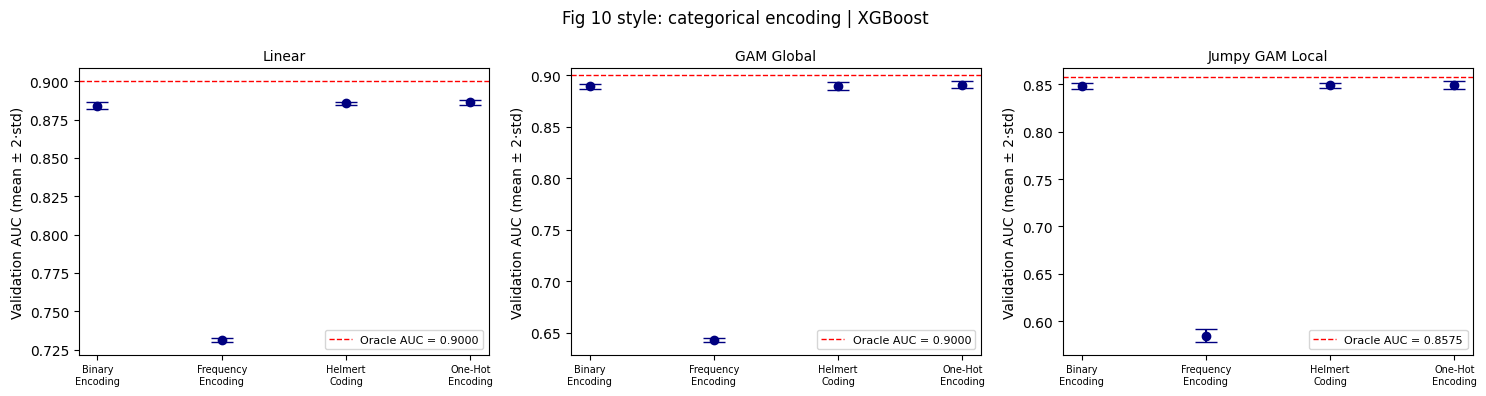

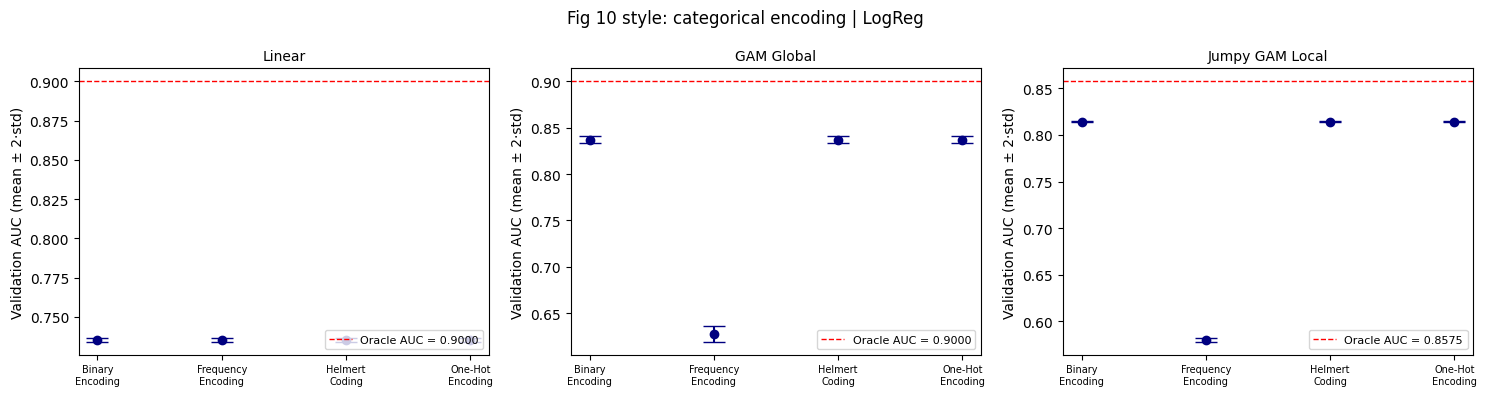


====== OBSERVATION CHECKS (categorical encoding) ======
  obs    dataset                                               evidence verdict    algo
Obs 6     linear              Frequency AUC 0.7314 vs baaki best 0.8863 ✔ holds XGBoost
Obs 7     linear OHE 0.8863 vs Helmert 0.8857; max |pred diff|=3.19e-01 ✔ holds XGBoost
Obs 6 gam_global              Frequency AUC 0.6428 vs baaki best 0.8907 ✔ holds XGBoost
Obs 7 gam_global OHE 0.8907 vs Helmert 0.8899; max |pred diff|=3.11e-01 ✔ holds XGBoost
Obs 6  jumpy_gam              Frequency AUC 0.5849 vs baaki best 0.8489 ✔ holds XGBoost
Obs 7  jumpy_gam OHE 0.8489 vs Helmert 0.8488; max |pred diff|=2.87e-01 ✔ holds XGBoost
Obs 6     linear              Frequency AUC 0.7356 vs baaki best 0.7355 ✘ check  LogReg
Obs 7     linear OHE 0.7355 vs Helmert 0.7355; max |pred diff|=2.93e-04 ✔ holds  LogReg
Obs 6 gam_global              Frequency AUC 0.6277 vs baaki best 0.8370 ✔ holds  LogReg
Obs 7 gam_global OHE 0.8370 vs Helmert 0.8370; max |pred diff|=

In [ ]:
# %%
# =====================================================================
# SHELL 7 | EXPERIMENT B: CATEGORICAL ENCODING  (Paper sec 2.2, Obs 6-7, Figs 10-11, Table 3)
#   4 encoders: One-Hot | Helmert (reverse) | Frequency | Binary
#   Dataset: "cat" variant (3 segments + indicator gatekeepers, Eq. 6-8)
# =====================================================================
ENC_METHODS = ["Binary Encoding", "Frequency Encoding", "Helmert Coding", "One-Hot Encoding"]

def helmert_matrix(k):
    """Reverse Helmert contrasts (Table 10): column j => pehle j levels = -1/(j+1), level j+1 = j/(j+1)."""
    M = np.zeros((k, max(k - 1, 0)))
    for j in range(1, k):
        M[:j, j - 1] = -1.0 / (j + 1); M[j, j - 1] = j / (j + 1)
    return M

def _lookup(M, idx):
    out = np.zeros((len(idx), M.shape[1])); ok = idx >= 0       # unseen category => zeros
    out[ok] = M[idx[ok]]; return out

def encode_cats(method, tr_c, va_c):
    """tr_c / va_c: sirf categorical columns. Encoder SIRF train se seekhta hai."""
    outs_tr, outs_va = [], []
    for c in tr_c.columns:
        levels = sorted(tr_c[c].astype(str).unique()); k = len(levels)
        idx = {v: i for i, v in enumerate(levels)}
        itr = tr_c[c].astype(str).map(idx).to_numpy()
        iva = va_c[c].astype(str).map(idx).fillna(-1).astype(int).to_numpy()
        if method == "One-Hot Encoding":                                   # Table 9
            M, names = np.eye(k), [f"{c}_{l}" for l in levels]
        elif method == "Helmert Coding":                                   # Table 10
            M = helmert_matrix(k); names = [f"{c}_helmert{j + 1}" for j in range(M.shape[1])]
        elif method == "Frequency Encoding":                               # Table 11
            fr = tr_c[c].astype(str).value_counts(normalize=True).reindex(levels).to_numpy()
            M, names = fr.reshape(-1, 1), [f"{c}_freq"]
        elif method == "Binary Encoding":                                  # Table 12: code 1..k ka binary
            nb = max(1, int(np.ceil(np.log2(k + 1)))); codes = np.arange(1, k + 1)
            M = np.array([[(cd >> (nb - 1 - b)) & 1 for b in range(nb)] for cd in codes], dtype=float)
            names = [f"{c}_bin{b + 1}" for b in range(nb)]
        else: raise ValueError(method)
        outs_tr.append(pd.DataFrame(_lookup(M, itr), columns=names, index=tr_c.index))
        outs_va.append(pd.DataFrame(_lookup(M, iva), columns=names, index=va_c.index))
    return pd.concat(outs_tr, axis=1), pd.concat(outs_va, axis=1)

def run_cat_encoding(get_split, params=None):
    res, wrows, diffs = [], [], []
    for run in range(N_RUNS):
        d = get_split(run); tr, va, meta = d["tr"], d["va"], d["meta"]; seed = SEED + run
        cats = meta["cat_cols"]; ytr, yva = tr["target"], va["target"]
        btr, bva = tr.drop(columns=["target"] + cats).copy(), va.drop(columns=["target"] + cats).copy()
        if btr.isna().any().any():                                          # real data: median fill
            med = btr.median(); btr, bva = btr.fillna(med), bva.fillna(med)
        preds = {}
        for method in ENC_METHODS:
            Etr, Eva = encode_cats(method, tr[cats].fillna("missing"), va[cats].fillna("missing"))
            Xtr, Xva = std_pair(pd.concat([btr, Etr], axis=1), pd.concat([bva, Eva], axis=1))
            for algo in ALGOS:
                m = make_model(algo, seed, params).fit(Xtr, ytr)
                p = m.predict_proba(Xva)[:, 1]; preds[(algo, method)] = p
                res.append(dict(run=run, algo=algo, method=method, n_features=Xtr.shape[1],
                                auc_train=auc_of(m, Xtr, ytr), auc_valid=roc_auc_score(yva, p), oracle=d["oracle"]))
                if algo == "XGBoost" and run == 0 and method in ("One-Hot Encoding", "Helmert Coding"):
                    for f, v in m.get_booster().get_score(importance_type="weight").items():   # Table 3
                        wrows.append(dict(method=method, feature=f, splits=v))
        for algo in ALGOS:
            diffs.append(dict(run=run, algo=algo, max_abs_pred_diff=float(np.max(np.abs(
                preds[(algo, "One-Hot Encoding")] - preds[(algo, "Helmert Coding")])))))
        print(f"    run {run + 1}/{N_RUNS} done", flush=True)
    return pd.DataFrame(res), pd.DataFrame(wrows), pd.DataFrame(diffs)

CAT_RES, CAT_W, CAT_DIFF = [], [], []
for form in FORMS:
    t0 = time.time(); print(f"[CAT] {FORM_NAME[form]}")
    paths = [csv_path(f"cat_{form}_{n}.csv") for n in ("results", "weights", "oh_vs_helmert")]
    if RESUME and all(os.path.exists(p) for p in paths):
        r, w, df_ = [pd.read_csv(p) for p in paths]; print("  [skip] results already exist")
    else:
        r, w, df_ = run_cat_encoding(SyntheticProvider(form, "cat").get, params_for(form, "cat"))
        for x, p in zip((r, w, df_), paths): x.to_csv(p, index=False)
    for x in (r, w, df_): x["form"] = form
    CAT_RES.append(r); CAT_W.append(w); CAT_DIFF.append(df_)
    print(f"  done in {time.time() - t0:.0f}s")
CAT_RES, CAT_W, CAT_DIFF = [pd.concat(x, ignore_index=True) for x in (CAT_RES, CAT_W, CAT_DIFF)]

cat_summary = (CAT_RES.groupby(["form", "algo", "method"]).agg(auc_mean=("auc_valid", "mean"), auc_std=("auc_valid", "std"),
               n_features=("n_features", "mean")).round(4))
cat_summary.to_csv(csv_path("cat_summary.csv"))
print("\n====== CATEGORICAL ENCODING SUMMARY ======"); print(cat_summary.to_string())

# ---- Table 3: OHE vs Helmert (XGBoost 'weight' = kitni baar split hua) ----
t3 = (CAT_W[CAT_W.form == "linear"].pivot_table(index="feature", columns="method", values="splits", aggfunc="first")
      .rename(columns={"One-Hot Encoding": "OHE splits", "Helmert Coding": "Helmert splits"}))
t3.to_csv(csv_path("table3_ohe_vs_helmert_linear.csv"))
print("\n====== TABLE 3 style (Linear): number of splits ======"); print(t3.to_string())

# ---- Figures: Fig 10 (synthetic) ----
for algo in ALGOS:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
    for ax, form in zip(axes, FORMS):
        d = CAT_RES[(CAT_RES.form == form) & (CAT_RES.algo == algo)]
        plot_methods(ax, d.groupby("method")["auc_valid"].agg(["mean", "std"]), ENC_METHODS,
                     f"{FORM_NAME[form]}", ORACLE_TARGET["cat"][form])
    fig.suptitle(f"Fig 10 style: categorical encoding | {algo}")
    save_fig(fig, f"fig10_cat_encoding_{algo}.png")

# ---- Observation checks ----
def cat_observations(algo):
    out = []
    S = CAT_RES[CAT_RES.algo == algo].groupby(["form", "method"])["auc_valid"].mean()
    for form in FORMS:
        fq = S[(form, "Frequency Encoding")]; oth = S[form].drop("Frequency Encoding")
        out.append(dict(obs="Obs 6", dataset=form, evidence=f"Frequency AUC {fq:.4f} vs baaki best {oth.max():.4f}",
                        verdict="✔ holds" if fq < oth.min() - 0.01 else "✘ check"))
        dd = CAT_DIFF[(CAT_DIFF.form == form) & (CAT_DIFF.algo == algo)]["max_abs_pred_diff"].max()
        ohe, hel = S[(form, "One-Hot Encoding")], S[(form, "Helmert Coding")]
        out.append(dict(obs="Obs 7", dataset=form, evidence=f"OHE {ohe:.4f} vs Helmert {hel:.4f}; max |pred diff|={dd:.2e}",
                        verdict="✔ holds" if abs(ohe - hel) < 0.002 else "✘ check"))
    return pd.DataFrame(out)

CAT_OBS = pd.concat([cat_observations(a).assign(algo=a) for a in ALGOS], ignore_index=True)
CAT_OBS.to_csv(csv_path("cat_observation_checks.csv"), index=False)
print("\n====== OBSERVATION CHECKS (categorical encoding) ======"); print(CAT_OBS.to_string(index=False))


[NULL] Linear
  [skip] null_linear_results.csv already exists
  done in 0s
[NULL] GAM Global
  [skip] null_gam_global_results.csv already exists
  done in 0s
[NULL] Jumpy GAM Local
  [skip] null_jumpy_gam_results.csv already exists
  done in 0s

====== NULL IMPUTATION SUMMARY ======
                                                 auc_mean  auc_std
form       algo    method                                         
gam_global LogReg  Clustering Imputation           0.8562   0.0010
                   Decile Imputation               0.8579   0.0024
                   Mean Imputation                 0.8608   0.0015
                   Median Imputation               0.8608   0.0015
                   Missing Indicator Imputation    0.8015   0.0096
                   No Missing                      0.9131   0.0016
                   Tree Imputation                 0.8517   0.0065
           XGBoost Clustering Imputation           0.8934   0.0081
                   Decile Imputation          

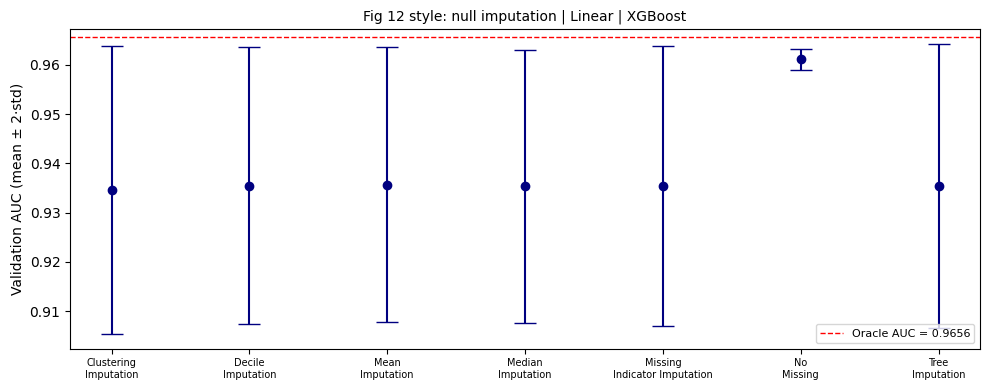

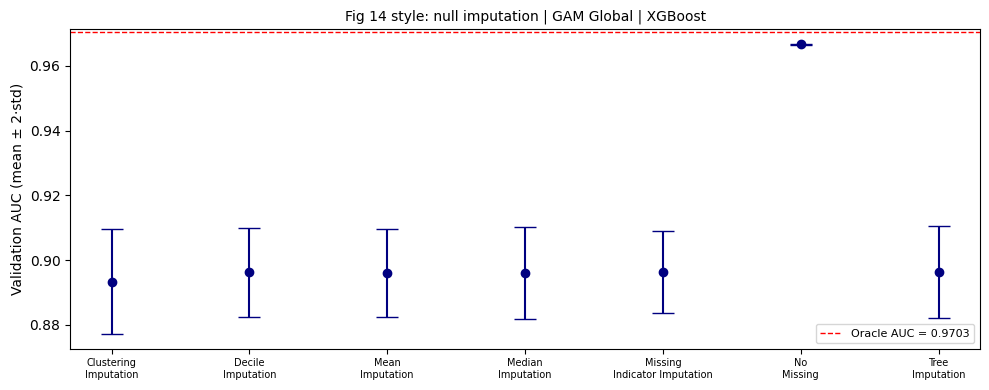

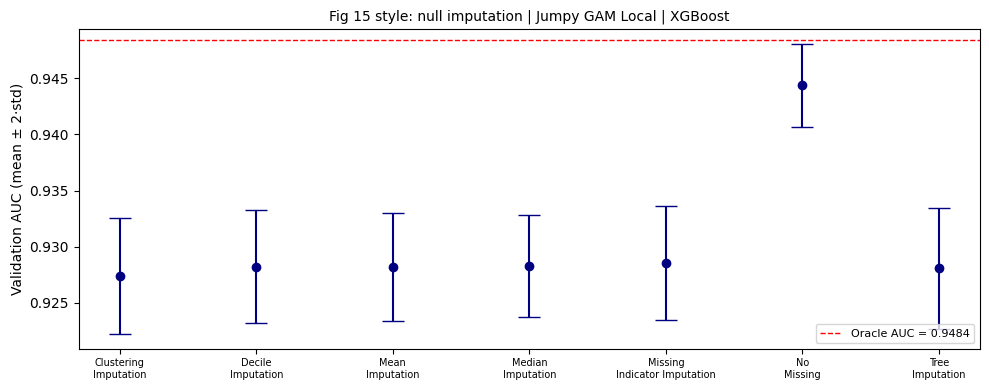

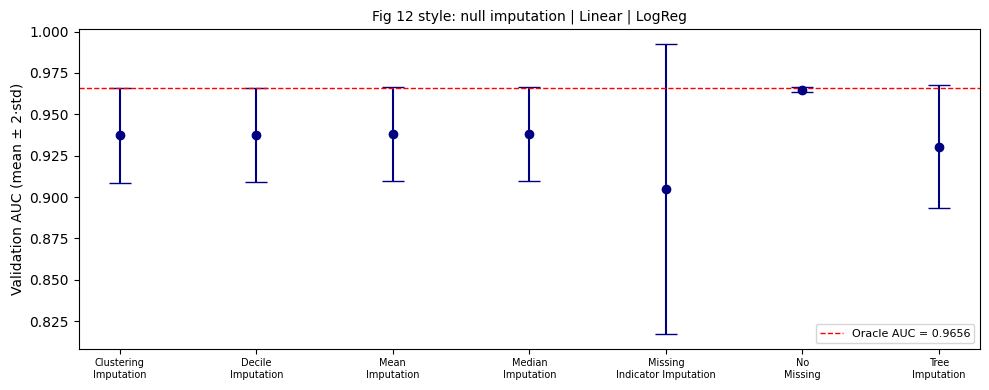

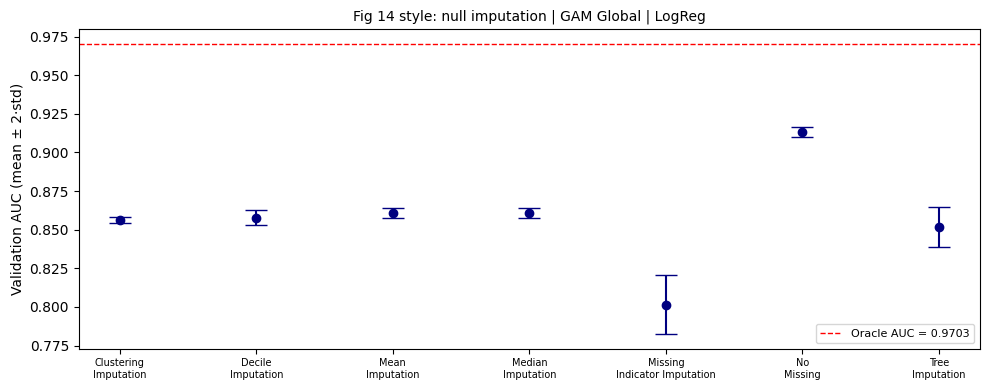

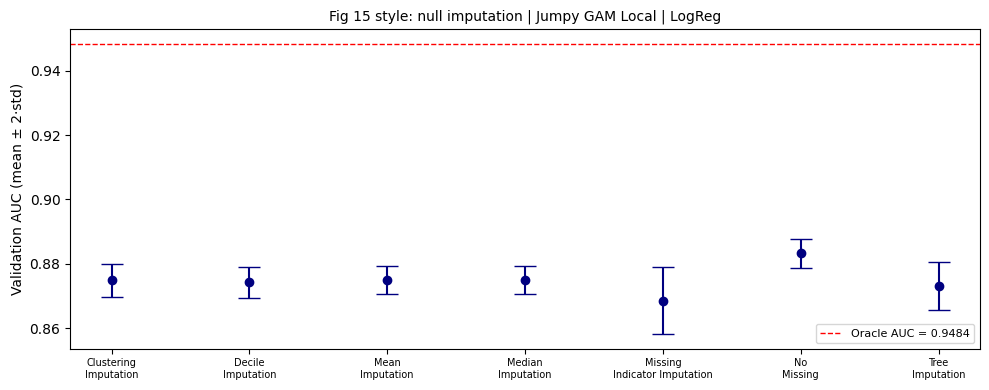


====== OBSERVATION CHECKS (null imputation) ======
   obs    dataset                                                                       evidence verdict    algo
 Obs 8     linear              best mean AUC: Mean Imputation (0.9356); Missing Indicator 0.9354 ✘ check XGBoost
 Obs 9     linear                                         mean/median/decile AUC spread = 0.0003 ✔ holds XGBoost
Obs 10     linear             most variable: Clustering Imputation (std 0.0146); Tree std 0.0144 ✘ check XGBoost
 Obs 8 gam_global              best mean AUC: Tree Imputation (0.8963); Missing Indicator 0.8963 ✘ check XGBoost
 Obs 9 gam_global                                         mean/median/decile AUC spread = 0.0003 ✔ holds XGBoost
Obs 10 gam_global             most variable: Clustering Imputation (std 0.0081); Tree std 0.0071 ✘ check XGBoost
 Obs 8  jumpy_gam best mean AUC: Missing Indicator Imputation (0.9285); Missing Indicator 0.9285 ✔ holds XGBoost
 Obs 9  jumpy_gam                           

In [ ]:
# %%
# =====================================================================
# SHELL 8 | EXPERIMENT C: NULL IMPUTATION  (Paper sec 2.3, Obs 8-10, Figs 12-15, Tables 13-18)
#   Methods: Mean | Median | Missing indicator | Decile | Clustering | Decision-tree  (+ "No Missing" baseline)
#   Dataset: "null" variant. 3 numeric features me 50% null inject (MCAR). Imputers SIRF train se seekhte hain.
# =====================================================================
from sklearn.cluster import MiniBatchKMeans
from sklearn.tree import DecisionTreeClassifier
from scipy import stats

IMP_METHODS = ["Clustering Imputation", "Decile Imputation", "Mean Imputation", "Median Imputation",
               "Missing Indicator Imputation", "No Missing", "Tree Imputation"]       # paper ki figures wala order
IMPUTERS = [m for m in IMP_METHODS if m != "No Missing"]

def inject_nulls(df, cols, rate, rng):
    out = df.copy()
    for c in cols: out.loc[rng.random(len(out)) < rate, c] = np.nan
    return out

def _fill(Xtr, Xva, c, val):
    Xtr[c] = Xtr[c].fillna(val); Xva[c] = Xva[c].fillna(val)

def imp_mean(Xtr, ytr, Xva, cols, seed):                       # Table 14
    Xtr, Xva = Xtr.copy(), Xva.copy()
    for c in cols: _fill(Xtr, Xva, c, Xtr[c].mean())
    return Xtr, Xva

def imp_median(Xtr, ytr, Xva, cols, seed):                     # Table 15
    Xtr, Xva = Xtr.copy(), Xva.copy()
    for c in cols: _fill(Xtr, Xva, c, Xtr[c].median())
    return Xtr, Xva

def imp_indicator(Xtr, ytr, Xva, cols, seed):                  # Table 16: -9999 + 0/1 indicator column
    Xtr, Xva = Xtr.copy(), Xva.copy()
    for c in cols:
        Xtr[c + "_missing"] = Xtr[c].isna().astype(float); Xva[c + "_missing"] = Xva[c].isna().astype(float)
        _fill(Xtr, Xva, c, -9999.0)
    return Xtr, Xva

def imp_decile(Xtr, ytr, Xva, cols, seed):
    """Feature ko 10 deciles me todo; har decile ka target-rate nikalo; missing group ka target-rate jis decile se
    sabse close ho, uska MEDIAN value imputation value."""
    Xtr, Xva = Xtr.copy(), Xva.copy()
    for c in cols:
        known = Xtr[c].notna()
        if (~known).sum() == 0 or known.sum() < 20: _fill(Xtr, Xva, c, Xtr[c].median()); continue
        bins = pd.qcut(Xtr.loc[known, c], 10, duplicates="drop")
        rate = ytr[known].groupby(bins, observed=True).mean()
        med = Xtr.loc[known, c].groupby(bins, observed=True).median()
        best = (rate - ytr[~known].mean()).abs().idxmin()
        _fill(Xtr, Xva, c, med[best])
    return Xtr, Xva

def imp_cluster(Xtr, ytr, Xva, cols, seed):
    """K-means se har row ko cluster do (mean-fill karke), phir cluster ka feature-mean = imputation value (Table 17-18)."""
    Xtr, Xva = Xtr.copy(), Xva.copy()
    mu, sd = Xtr.mean(), Xtr.std().replace(0, 1)
    Ztr, Zva = ((Xtr.fillna(mu) - mu) / sd).fillna(0), ((Xva.fillna(mu) - mu) / sd).fillna(0)
    km = MiniBatchKMeans(n_clusters=CLUSTER_K, random_state=seed, n_init=3, batch_size=2048).fit(Ztr)
    ctr, cva = km.labels_, km.predict(Zva)
    for c in cols:
        means = Xtr[c].groupby(ctr).mean()
        for X, cl in ((Xtr, ctr), (Xva, cva)):
            na = X[c].isna().to_numpy()
            X.loc[na, c] = pd.Series(cl[na]).map(means).fillna(Xtr[c].mean()).to_numpy()
    return Xtr, Xva

def imp_tree(Xtr, ytr, Xva, cols, seed):
    """Har feature pe single-feature CART; har leaf ka target vs missing-group ka target ka t-test;
    sabse chhote |t| wale leaf ka median value = imputation value."""
    Xtr, Xva = Xtr.copy(), Xva.copy()
    for c in cols:
        known = Xtr[c].notna().to_numpy()
        if (~known).sum() == 0 or known.sum() < 40: _fill(Xtr, Xva, c, Xtr[c].median()); continue
        x, y, ym = Xtr.loc[known, [c]].to_numpy(), ytr[known].to_numpy(), ytr[~known].to_numpy()
        tree = DecisionTreeClassifier(max_leaf_nodes=TREE_IMPUTE_LEAVES, min_samples_leaf=max(20, len(x) // 200),
                                      random_state=seed).fit(x, y)
        leaf = tree.apply(x); best, bt = None, np.inf
        for L in np.unique(leaf):
            yl = y[leaf == L]
            t = abs(stats.ttest_ind(yl, ym, equal_var=False).statistic)
            if np.isnan(t): t = abs(yl.mean() - ym.mean()) * 1e6
            if t < bt: bt, best = t, L
        _fill(Xtr, Xva, c, np.median(x[leaf == best]))
    return Xtr, Xva

IMPUTE_FN = {"Mean Imputation": imp_mean, "Median Imputation": imp_median, "Missing Indicator Imputation": imp_indicator,
             "Decile Imputation": imp_decile, "Clustering Imputation": imp_cluster, "Tree Imputation": imp_tree}

def run_null_imputation(get_split, params=None):
    res = []
    for run in range(N_RUNS):
        d = get_split(run); tr, va, meta = d["tr"], d["va"], d["meta"]; seed = SEED + run
        cats = meta["cat_cols"]; num = meta["num_cols"] + meta["noise_cols"]
        ytr, yva = tr["target"], va["target"]
        if meta.get("inject_nulls", True):                          # synthetic: 3 informative features me 50% null
            rng = np.random.default_rng(seed)
            miss = list(rng.choice(meta["num_cols"], size=min(N_NULL_FEATURES, len(meta["num_cols"])), replace=False))
            trN, vaN = inject_nulls(tr, miss, NULL_RATE, rng), inject_nulls(va, miss, NULL_RATE, rng)
        else:                                                       # real data: jo NaN already hain
            trN, vaN = tr, va; miss = [c for c in num if trN[c].isna().any()]
        for method in IMP_METHODS:
            if method == "No Missing":
                if not meta.get("inject_nulls", True): continue
                Ntr, Nva = tr[num].copy(), va[num].copy()
            else:
                Ntr, Nva = IMPUTE_FN[method](trN[num], ytr, vaN[num], miss, seed)
            Ftr, Fva = pd.concat([Ntr, trN[cats].astype(object).where(trN[cats].notna(), "missing")], axis=1), \
                       pd.concat([Nva, vaN[cats].astype(object).where(vaN[cats].notna(), "missing")], axis=1)
            Ftr, Fva = ohe_pair(Ftr, Fva, cats); Ftr, Fva = std_pair(Ftr, Fva)
            for algo in ALGOS:
                m = make_model(algo, seed, params).fit(Ftr, ytr)
                res.append(dict(run=run, algo=algo, method=method, auc_train=auc_of(m, Ftr, ytr),
                                auc_valid=auc_of(m, Fva, yva), n_features=Ftr.shape[1], oracle=d["oracle"]))
        print(f"    run {run + 1}/{N_RUNS} done", flush=True)
    return pd.DataFrame(res)

NULL_RES = []
for form in FORMS:
    t0 = time.time(); print(f"[NULL] {FORM_NAME[form]}")
    r = cached(f"null_{form}_results.csv", lambda: run_null_imputation(SyntheticProvider(form, "null").get, params_for(form, "null")))
    r["form"] = form; NULL_RES.append(r); print(f"  done in {time.time() - t0:.0f}s")
NULL_RES = pd.concat(NULL_RES, ignore_index=True)

null_summary = (NULL_RES.groupby(["form", "algo", "method"]).agg(auc_mean=("auc_valid", "mean"), auc_std=("auc_valid", "std")).round(4))
null_summary.to_csv(csv_path("null_summary.csv"))
print("\n====== NULL IMPUTATION SUMMARY ======"); print(null_summary.to_string())

# ---- Figures: Fig 12 (Linear), Fig 14 (GAM Global), Fig 15 (Jumpy GAM Local) ----
FIGNO = {"linear": 12, "gam_global": 14, "jumpy_gam": 15}
for algo in ALGOS:
    for form in FORMS:
        d = NULL_RES[(NULL_RES.form == form) & (NULL_RES.algo == algo)]
        fig, ax = plt.subplots(figsize=(10, 4))
        plot_methods(ax, d.groupby("method")["auc_valid"].agg(["mean", "std"]), IMP_METHODS,
                     f"Fig {FIGNO[form]} style: null imputation | {FORM_NAME[form]} | {algo}", ORACLE_TARGET["null"][form])
        save_fig(fig, f"fig{FIGNO[form]}_null_{form}_{algo}.png")

# ---- Observation checks 8-10 ----
def null_observations(algo):
    out = []
    S = NULL_RES[(NULL_RES.algo == algo) & (NULL_RES.method != "No Missing")].groupby(["form", "method"])["auc_valid"].agg(["mean", "std"])
    for form in FORMS:
        s = S.loc[form]; best = s["mean"].idxmax()
        out.append(dict(obs="Obs 8", dataset=form, evidence=f"best mean AUC: {best} ({s['mean'].max():.4f}); Missing Indicator {s.loc['Missing Indicator Imputation','mean']:.4f}",
                        verdict="✔ holds" if best == "Missing Indicator Imputation" else "✘ check"))
        sp = s.loc[["Mean Imputation", "Median Imputation", "Decile Imputation"], "mean"]
        out.append(dict(obs="Obs 9", dataset=form, evidence=f"mean/median/decile AUC spread = {sp.max() - sp.min():.4f}",
                        verdict="✔ holds" if sp.max() - sp.min() < 0.01 else "✘ check"))
        out.append(dict(obs="Obs 10", dataset=form, evidence=f"most variable: {s['std'].idxmax()} (std {s['std'].max():.4f}); Tree std {s.loc['Tree Imputation','std']:.4f}",
                        verdict="✔ holds" if s["std"].idxmax() == "Tree Imputation" else "✘ check"))
    return pd.DataFrame(out)

NULL_OBS = pd.concat([null_observations(a).assign(algo=a) for a in ALGOS], ignore_index=True)
NULL_OBS.to_csv(csv_path("null_observation_checks.csv"), index=False)
print("\n====== OBSERVATION CHECKS (null imputation) ======"); print(NULL_OBS.to_string(index=False))


In [ ]:
# %%
# =====================================================================
# SHELL 9 | LENDING CLUB (REAL-WORLD DATA)  -- OPTIONAL  (Paper Figs 4, 11, 13)
#   Kaggle "Lending Club Loan Data" (loan.csv) download karke DRIVE_FOLDER me rakho (LC_FILENAME).
#   Agar file nahi hai to ye shell khud skip ho jayega.
#   Paper ki preprocessing: 99% null columns, identity columns, current-delinquency/leakage columns hata do.
#   Target: Charged Off = 1, Current = 0.  70 numeric + 10 categorical features (paper jaisa).
#   NOTE: column-selection heuristic hai -- print hui lists ek baar dekh lena.
# =====================================================================
LC_ID_COLS = ["id", "member_id", "url", "desc", "title", "emp_title", "zip_code", "policy_code"]
LC_LEAK_PATTERNS = ["pymnt", "recover", "collection_recovery_fee", "out_prncp", "total_rec_", "last_credit_pull",
                    "settlement", "hardship", "acc_now_delinq", "next_pymnt"]

def load_lending_club():
    path = os.path.join(BASE_DIR, LC_FILENAME)
    if not os.path.exists(path):
        print(f"[LC] {path} nahi mila -> Lending Club part skip."); return None
    raw = pd.read_csv(path, low_memory=False)
    raw = raw[raw["loan_status"].isin(["Charged Off", "Current"])]
    if len(raw) > LC_ROWS: raw = raw.sample(LC_ROWS, random_state=SEED)
    raw = raw.reset_index(drop=True)
    y = (raw["loan_status"] == "Charged Off").astype(int)
    X = raw.drop(columns=["loan_status"])
    X = X.loc[:, X.isna().mean() < 0.99]                                              # 99% null columns
    drop = [c for c in X.columns if c in LC_ID_COLS or any(p in c for p in LC_LEAK_PATTERNS)]
    X = X.drop(columns=drop)
    num = [c for c in X.select_dtypes(include=[np.number]).columns if X[c].nunique() > 1]
    num = sorted(num, key=lambda c: X[c].isna().mean())[:70]
    cats = [c for c in X.select_dtypes(exclude=[np.number]).columns if 2 <= X[c].nunique() <= 30]
    cats = sorted(cats, key=lambda c: X[c].isna().mean())[:10]
    df = pd.concat([X[num], X[cats]], axis=1); df["target"] = y
    meta = dict(num_cols=num, noise_cols=[], cat_cols=cats, inject_nulls=False)
    print(f"[LC] rows={len(df):,} | numeric={len(num)} | categorical={len(cats)} | charged-off rate={y.mean():.3f}")
    print("[LC] categorical used:", cats); print("[LC] dropped (leak/id):", drop)
    return df, meta

class LendingClubProvider:
    def __init__(self, df, meta): self.df, self.meta = df, meta
    def get(self, run):
        idx = np.random.default_rng(SEED + run).permutation(len(self.df))
        n_tr = min(TRAIN_ROWS, int(0.7 * len(self.df))); n_va = min(VALID_ROWS, len(self.df) - n_tr)
        return dict(tr=self.df.iloc[idx[:n_tr]].reset_index(drop=True),
                    va=self.df.iloc[idx[n_tr:n_tr + n_va]].reset_index(drop=True), meta=self.meta, oracle=None)

LC_DATA = load_lending_club()
if LC_DATA is not None:
    prov = LendingClubProvider(*LC_DATA)
    LC_FS  = cached("lc_fs_results.csv",   lambda: run_feature_selection(prov.get, LC_N_SELECT)[0])
    LC_CAT = cached("lc_cat_results.csv",  lambda: run_cat_encoding(prov.get)[0])
    LC_NUL = cached("lc_null_results.csv", lambda: run_null_imputation(prov.get))
    for algo in ALGOS:
        for fig_no, df, methods, name in [(4, LC_FS, FS_METHODS, "feature selection"),
                                          (11, LC_CAT, ENC_METHODS, "categorical encoding"),
                                          (13, LC_NUL, IMP_METHODS, "null imputation")]:
            fig, ax = plt.subplots(figsize=(10, 4))
            plot_methods(ax, df[df.algo == algo].groupby("method")["auc_valid"].agg(["mean", "std"]), methods,
                         f"Fig {fig_no} style: Lending Club | {name} | {algo}")
            save_fig(fig, f"fig{fig_no}_lending_club_{algo}.png")
    print("\n====== LENDING CLUB SUMMARY (valid AUC mean) ======")
    for nm, df in [("Feature selection", LC_FS), ("Categorical encoding", LC_CAT), ("Null imputation", LC_NUL)]:
        print(f"\n{nm}"); print(df.groupby(["algo", "method"])["auc_valid"].agg(["mean", "std"]).round(4).to_string())


[LC] /content/drive/MyDrive/paper2A_group9_all/loan.csv nahi mila -> Lending Club part skip.


In [ ]:

# %%
# =====================================================================
# SHELL 10 | FINAL REPORT  -- sab observations ek jagah (Obs 1-10)
#   Paper ke verdicts XGBoost pe based hain, isliye yahan XGBoost (agar ALGOS me hai) ke results use hote hain.
#   LogReg wale results alag CSV/figures me hain (Group 9 ka extra comparison).
# =====================================================================
PAPER_ALGO = "XGBoost" if "XGBoost" in ALGOS else ALGOS[0]
ALL_OBS = pd.concat([FS_OBS, CAT_OBS, NULL_OBS], ignore_index=True)
ALL_OBS = ALL_OBS[ALL_OBS.algo == PAPER_ALGO]
ALL_OBS["n"] = ALL_OBS["obs"].str.extract(r"(\d+)").astype(int)

CLAIM = {
    1: "Simple data me feature-selection method ka choice trivial; sirf Pearson/Spearman corr-reduction exception",
    2: "Permutation importance: local-interaction data me high variability (+ noise features chun leta hai)",
    3: "LASSO zaroorat se zyada features chunta hai, performance me gain nahi",
    4: "XGBoost importance: gain > weight",
    5: "XGBoost gain sabse consistent method",
    6: "Frequency encoding rigid/structured categories pe poorly perform karta hai",
    7: "Helmert aur OHE ka performance (tree models me) same",
    8: "Missing-indicator imputation sabse achha (score + variability)",
    9: "Mean / median / decile imputation lagbhag same",
    10: "Tree imputation sabse variable, recommend nahi",
}
rows = []
for n, g in ALL_OBS.groupby("n"):
    ok = (g["verdict"].str.contains("✔")).sum()
    rows.append(dict(obs=f"Obs {n}", claim=CLAIM[n], datasets_holding=f"{ok}/{len(g)}",
                     verdict="✔ validated" if ok == len(g) else ("~ partially" if ok > 0 else "✘ not reproduced")))
FINAL = pd.DataFrame(rows)
FINAL.to_csv(csv_path("FINAL_observation_summary.csv"), index=False)
pd.set_option("display.max_colwidth", 110)
print(f"====== PAPER 2A: OBSERVATIONS (algo = {PAPER_ALGO}) ======")
print(FINAL.to_string(index=False))
print("\nDetail (dataset-wise):"); print(ALL_OBS.drop(columns=["n"]).to_string(index=False))

print("\nFiles:")
print(" results :", sorted(os.listdir(RES_DIR)))
print(" figures :", len(os.listdir(FIG_DIR)), "PNG files ->", FIG_DIR)
print(" datasets:", sorted(os.listdir(DATA_DIR)))

====== PAPER 2A: OBSERVATIONS (algo = XGBoost) ======
   obs                                                                                                     claim datasets_holding     verdict
 Obs 1 Simple data me feature-selection method ka choice trivial; sirf Pearson/Spearman corr-reduction exception              1/3 ~ partially
 Obs 2       Permutation importance: local-interaction data me high variability (+ noise features chun leta hai)              1/1 ✔ validated
 Obs 3                                     LASSO zaroorat se zyada features chunta hai, performance me gain nahi              3/3 ✔ validated
 Obs 4                                                                         XGBoost importance: gain > weight              1/3 ~ partially
 Obs 5                                                                      XGBoost gain sabse consistent method              3/3 ✔ validated
 Obs 6                                Frequency encoding rigid/structured categories pe poorly